# Ancient Environmental Metagenomics (AEMG01)
## Day 5 · Part 3: Alignment-based taxonomic profiling and damage at metagenome scale – ngsLCA, metaDMG and bamdam

<a href="https://colab.research.google.com/github/NikolayOskolkov/AncientEnvironmentalMetagenomics/blob/main/notebooks/Day5_LCA_damage_shortcut.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

> **Prerequisites:** `Day1_setup_shortcut.ipynb` (`course_paths.json`), `Day1_QC_shortcut.ipynb` (trimmed reads in `03_TRIMMED/`) and – optionally, to choose the microbial references – `Day2_TaxonomicProfiling_shortcut.ipynb` (abundance matrix).

On Day 2 we profiled the samples with **k-mer classifiers** (KrakenUniq, Kraken2) and on Day 3 we followed up one hit with an alignment. In this practical we go the other way round, as is common in **sedimentary ancient DNA (sedaDNA)** studies of plants and animals: we **align all reads** to reference genomes first and infer the taxonomy and the damage **from the alignments** – with no k-mer classification and no per-hit follow-up.

### Learning outcomes
After this practical you will be able to:

* explain why alignment against **split reference indexes** needs far less memory than k-mer classification against one huge database,
* build separate Bowtie2 indexes for **microbes, plants, mammals, other vertebrates and invertebrates**, align each sample to all of them, and **merge** the alignments,
* assign each read to its **lowest common ancestor (LCA)** with **ngsLCA**, using a similarity window, and visualise the profiles with the **ngsLCA R package**,
* estimate **ancient DNA damage for every taxon** in every sample with **metaDMG**,
* compute per-taxon **authentication metrics** (damage, read length, duplicity, complexity) and damage plots with **bamdam**.

<p align="center">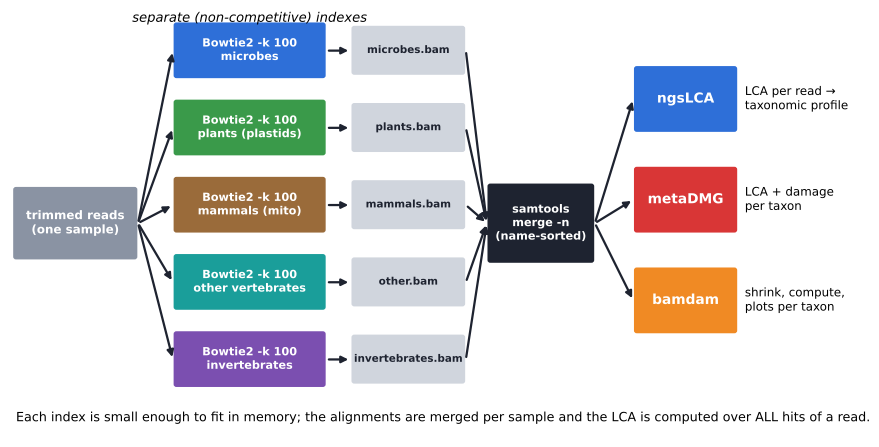<br><em>Today's workflow: one sample is aligned to five separate indexes; the BAM files are merged and analysed with ngsLCA, metaDMG and bamdam.</em></p>

---
## Scientific background

### Why align instead of classifying k-mers?

Ancient environmental DNA is dominated by **microbes**, but the questions are often about **plants and animals**: which vegetation grew around a lake 10,000 years ago, which mammals lived there? For eukaryotes, k-mer classifiers have two problems:

1. **Database size.** Eukaryotic genomes are huge (a single conifer genome has > 20 Gbp). A k-mer database of all plants, animals and microbes would need **terabytes of RAM**, because a k-mer classifier keeps its **entire** database in memory (KrakenUniq even offers `--preload-size` for exactly this reason, Day 2).
2. **Evidence.** A k-mer hit gives no alignment: no edit distance, no damage pattern, no coverage. For sedaDNA these are needed anyway (Day 3).

**Alignment** with Bowtie2 or BWA needs only the **index** of the reference sequences in memory, and – crucially – the reference can be **split into chunks**. Each chunk is aligned separately and the results are merged afterwards. The memory needed is that of the **largest chunk**, not of the whole database:

<p align="center">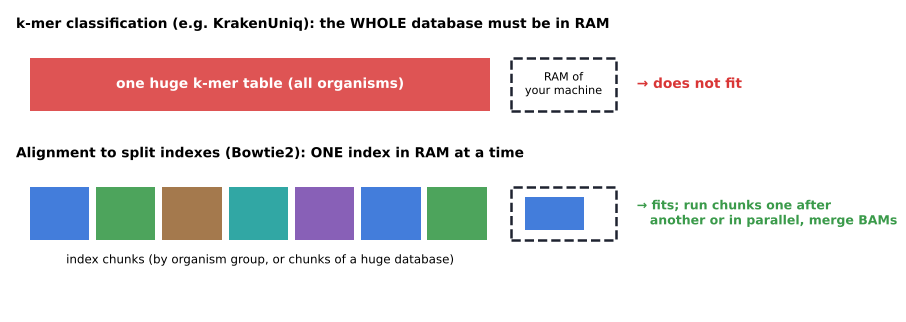</p>

This is the strategy of the **Holi** pipeline (Wang et al. 2021, *Nature*, [doi:10.1038/s41586-021-04016-x](https://doi.org/10.1038/s41586-021-04016-x)): reads were aligned with Bowtie2 to the NCBI nucleotide database and RefSeq split into many index chunks, the BAM files were merged, and the taxonomy was assigned with an LCA algorithm (later released as ngsLCA). The price is **time** (alignment is slower than k-mer look-up) and **disk** (BAM files with many alignments per read) – but time and disk are cheaper than RAM: you can run chunks one after the other on a modest machine.

### Separate indexes for organism groups: non-competitive mapping

In practice the reference is often split **by organism group**: e.g. **microbes, plants, mammals, other vertebrates and invertebrates**, each with its own Bowtie2 index. Each read is aligned to every index **independently**. This is **non-competitive** mapping: within one index the aligner reports a read's best hits, but the indexes do not "compete" for the read – a bacterial read can obtain a hit in the plant index if a chloroplast region resembles a bacterial gene.

That is not a problem as long as we **merge** the alignments of all indexes and then compute the LCA over **all** hits of a read:
* a read with good hits only in the plant index stays a plant read,
* a read with equally good hits in the bacterial **and** the plant index is assigned to their LCA – high up in the tree ("cellular organisms"), i.e. it is effectively **not** counted as a plant.

So merging + LCA turns many separate, non-competitive alignments into a conservative, competitive-like assignment.

> ⚠️ Two technical requirements follow from this: (1) Bowtie2 must report **multiple** alignments per read (`-k`), otherwise there is nothing to compute an LCA from; (2) all alignments of a read must be **next to each other** in the BAM file – the files are **sorted by read name** (`samtools sort -n`) and merged in that order (`samtools merge -n`).

### The lowest common ancestor with a similarity window – ngsLCA

<p align="center">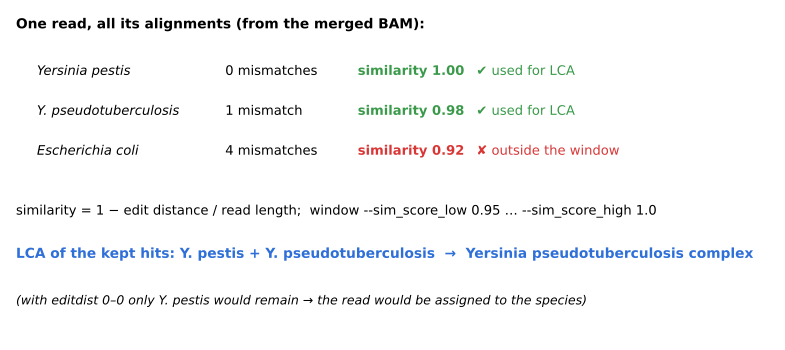<br><em>ngsLCA considers only alignments within a similarity (or edit distance) window, and assigns the read to the lowest common ancestor of their taxa.</em></p>

[**ngsLCA**](https://github.com/miwipe/ngsLCA) (Wang et al. 2022, *Methods in Ecology and Evolution*, [doi:10.1111/2041-210X.14006](https://doi.org/10.1111/2041-210X.14006)) is a fast C/C++ program plus an R package. For every read it collects all alignments, keeps those whose **similarity to the reference** lies in a chosen window (similarity = 1 − edit distance / read length), maps each reference sequence to its NCBI taxon via an **accession → taxID** table, and assigns the read to the **LCA** of those taxa in the NCBI taxonomy. A strict window (e.g. 0.95–1.0) excludes hits to distant relatives, so the LCA does not climb too high; a wider window gives more conservative assignments. Because ancient reads carry damage-induced mismatches, the window must not be too strict. The R package turns the per-read output into taxonomic profiles, filters and plots.

### Ancient DNA damage for every taxon – metaDMG

On Day 3 we measured damage for **one** organism. A sedaDNA sample can contain **thousands** of taxa. [**metaDMG**](https://github.com/metaDMG-dev/metaDMG-cpp) (Michelsen et al. 2022, bioRxiv, [doi:10.1101/2022.12.06.519264](https://doi.org/10.1101/2022.12.06.519264)) computes the LCA (with the ngsLCA algorithm) **and at the same time** counts C→T and G→A substitutions along the reads **for every node of the taxonomic tree**. It then fits a damage model (based on the model of Briggs et al. 2007, *PNAS*, [doi:10.1073/pnas.0704665104](https://doi.org/10.1073/pnas.0704665104)) to every taxon:

| Parameter | Meaning |
|---|---|
| **A** | damage **amplitude**: estimated C→T frequency at the first position, above background – the main damage measure |
| **q** | how fast damage **decays** with distance from the read end |
| **c** | background substitution rate (sequencing errors, divergence from the reference) |
| **phi** | over-dispersion (extra variance between reads) |
| **Zfit** | **significance** of the damage: roughly the number of standard deviations A lies above 0 – a fit with Zfit > 2 is considered significant |

metaDMG works on all taxa at once, in minutes, and makes damage a routine part of every taxonomic profile.

### Post-LCA authentication – bamdam

[**bamdam**](https://github.com/bdesanctis/bamdam) (De Sanctis et al. 2025, *Genome Biology*, [doi:10.1186/s13059-025-03879-x](https://doi.org/10.1186/s13059-025-03879-x)) is a toolkit for the last step of such pipelines: it takes the read-sorted BAM and the ngsLCA output and computes, per taxon, a table of **authentication metrics** – number of reads, **damage** (C→T at position 1), **mean read length**, **duplicity** (are many reads PCR duplicates?), **read complexity** (DUST score – low-complexity reads cause false hits), **unique k-mers**, **average identity to the reference (ANI)** – and makes damage plots, read-length plots and Krona charts. Its `shrink` command first removes taxa with too few reads, making the files much smaller.

<p align="center"><img src="https://raw.githubusercontent.com/NikolayOskolkov/AncientEnvironmentalMetagenomics/main/images/metagenomic_approaches.png" width="640"><br><em>Alignment, k-mer classification and assembly – today we use the alignment route for profiling.</em></p>

---
## 1. Session setup

### 1.1 Install conda
`condacolab.install()` restarts the kernel – the *"session crashed"* message is expected; continue with the next cell.

In [1]:
!pip install -q condacolab
import condacolab
condacolab.install()


📢 Announcement 📢
condacolab==0.2 will be released soon! Try it with:

    !pip install -q https://github.com/conda-incubator/condacolab/archive/main.zip
    import condacolab
    condacolab.install()

0.2.x introduces a new installation method based on Pixi, with customizable Python versions.
This may be breaking for your workflow. If that's the case, please report it at
https://github.com/conda-incubator/condacolab and pin your `pip install` command to:

    !pip install -q 'condacolab==0.1.*'

⏬ Downloading https://github.com/conda-forge/miniforge/releases/download/26.3.2-3/Miniforge3-26.3.2-3-Linux-x86_64.sh...
📦 Installing...
📌 Adjusting configuration...
🩹 Patching environment...
⏲ Done in 0:00:15
🔁 Restarting kernel...


In [1]:
import shutil, sys
mamba = shutil.which("mamba")
print("Python :", sys.executable)
print("mamba  :", mamba or "NOT FOUND")
assert mamba, "conda/mamba is not installed – run the condacolab.install() cell above and wait for the restart"
!mamba --version

Python : /usr/bin/python3.real
mamba  : /usr/local/bin/mamba
2.5.0


### 1.2 Mount Google Drive

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


### 1.3 Install today's software

| Tool | Used for | Installed from |
|---|---|---|
| Bowtie2, samtools | alignment, sorting and merging | Bioconda |
| [`ngslca`](https://bioconda.github.io/recipes/ngslca/README.html) | ngsLCA main program | Bioconda |
| [`metadmg`](https://anaconda.org/bioconda/metadmg) | metaDMG-cpp (`lca`, `dfit`, `aggregate`) | Bioconda |
| [`ncbi-datasets-cli`](https://www.ncbi.nlm.nih.gov/datasets/docs/v2/) | downloading reference genomes from NCBI | conda-forge |
| Krona | interactive charts from bamdam | Bioconda |
| [bamdam](https://pypi.org/project/bamdam/) | post-LCA authentication | PyPI (`pip`) |
| R + [ngsLCA R package](https://github.com/wyc661217/ngsLCA) | profiles and plots | conda environment `renv` + CRAN or GitHub |

The R package and its dependencies go into their own environment `renv` (as on Day 4). Logs are written to `/content/install_*.log`. This takes 5–10 minutes.

In [3]:
!mamba install -y -q -c conda-forge -c bioconda bowtie2 samtools ngslca metadmg krona ncbi-datasets-cli pandas > /content/install_base.log 2>&1
!pip install -q bamdam > /content/install_bamdam.log 2>&1
!mamba create -y -q -n renv -c conda-forge r-base r-ggplot2 r-reshape r-reshape2 r-vegan r-gplots r-readr r-rcolorbrewer r-dplyr > /content/install_renv.log 2>&1
print("done")

done


Install the **ngsLCA R package** into the `renv` environment. The package is pure R, but several of its dependencies (e.g. `analogue` and `rioja`, used for stratigraphic plots) contain compiled code, and compiling them inside a conda R often fails. So we:

1. install as many dependencies as possible as ready-made **conda-forge** packages (`r-<name>`), one by one, so that a package missing from conda-forge does not stop the others;
2. try to install ngsLCA from **CRAN**; if the package is not available there (it has been archived from CRAN at times),
3. install it from the authors' **GitHub** repository [wyc661217/ngsLCA](https://github.com/wyc661217/ngsLCA) with `remotes::install_github()`.

If all fails, the last lines of the log are printed. The Python profile plots in Section 4.2 do not need the R package.

In [4]:
%%bash
ENVS=$(conda info --base)/envs
# 1. dependencies from conda-forge, one at a time (a missing package only prints a warning)
for pkg in r-remotes r-analogue r-rioja r-plyr r-scales r-tidyr r-stringr r-magrittr r-taxonomizr r-ggrepel; do
  mamba install -y -q -n renv -c conda-forge $pkg >> /content/install_renv_extra.log 2>&1     && echo "  conda-forge: $pkg ✓" || echo "  conda-forge: $pkg not available – R will try to install it"
done
export PATH=$ENVS/renv/bin:$PATH
cat > /content/install_ngsLCA.R <<'RS'
options(repos = c(CRAN = "https://cloud.r-project.org"), Ncpus = 2)
ok <- function() requireNamespace("ngsLCA", quietly = TRUE)
if (!ok()) { message(">> trying CRAN");   try(install.packages("ngsLCA")) }
if (!ok()) { message(">> trying GitHub");
             if (!requireNamespace("remotes", quietly = TRUE)) install.packages("remotes")
             try(remotes::install_github("wyc661217/ngsLCA", upgrade = "never")) }
if (!ok()) quit(status = 1)
RS
Rscript /content/install_ngsLCA.R > /content/install_ngsLCA_R.log 2>&1
if Rscript -e 'suppressMessages(library(ngsLCA)); cat("✅ ngsLCA R package", as.character(packageVersion("ngsLCA")), "\n")'; then
  :
else
  echo "❌ ngsLCA R package NOT installed. Last lines of /content/install_ngsLCA_R.log:"
  grep -iE "error|fail|not available|non-zero" /content/install_ngsLCA_R.log | tail -n 15
fi

  conda-forge: r-remotes ✓
  conda-forge: r-analogue ✓
  conda-forge: r-rioja ✓
  conda-forge: r-plyr ✓
  conda-forge: r-scales ✓
  conda-forge: r-tidyr ✓
  conda-forge: r-stringr ✓
  conda-forge: r-magrittr ✓
  conda-forge: r-taxonomizr ✓
  conda-forge: r-ggrepel ✓
❌ ngsLCA R package NOT installed. Last lines of /content/install_ngsLCA_R.log:
code for methods in class “GLMrespMod” was not checked for suspicious field assignments (recommended package ‘codetools’ not available?)
-- Performing Test HAVE_THREAD_LOCAL_STORAGE - Failed
code for methods in class “GlobalOption” was not checked for suspicious field assignments (recommended package ‘codetools’ not available?)
code for methods in class “merPredD” was not checked for suspicious field assignments (recommended package ‘codetools’ not available?)
code for methods in class “lmResp” was not checked for suspicious field assignments (recommended package ‘codetools’ not available?)
code for methods in class “lmerResp” was not checked for

Error in library(ngsLCA) : there is no package called ‘ngsLCA’
Calls: suppressMessages -> withCallingHandlers -> library
Execution halted


In [5]:
%%bash
ENVS=$(conda info --base)/envs
mamba install -y -q -n renv -c conda-forge -c bioconda bioconductor-complexheatmap r-codetools \
  > /content/install_complexheatmap.log 2>&1 && echo "✓ ComplexHeatmap" || tail -n 5 /content/install_complexheatmap.log
export PATH=$ENVS/renv/bin:$PATH
Rscript -e 'options(repos = c(CRAN = "https://cloud.r-project.org")); if (!requireNamespace("ngsLCA", quietly = TRUE)) install.packages("ngsLCA")' \
  > /content/install_ngsLCA_R.log 2>&1
Rscript -e 'suppressMessages(library(ngsLCA)); cat("✅ ngsLCA R package", as.character(packageVersion("ngsLCA")), "\n")' \
  || { echo "❌"; grep -iE "^ERROR|error:|not available for|non-zero" /content/install_ngsLCA_R.log | tail -n 10; }

✓ ComplexHeatmap
❌
package ‘ngsLCA’ is not available for this version of R


Error in library(ngsLCA) : there is no package called ‘ngsLCA’
Calls: suppressMessages -> withCallingHandlers -> library
Execution halted


In [6]:
%%bash
export PATH=$(conda info --base)/envs/renv/bin:$PATH
Rscript -e 'options(repos = c(CRAN = "https://cloud.r-project.org")); remotes::install_github("wyc661217/ngsLCA", upgrade = "never")' \
  > /content/install_ngsLCA_R.log 2>&1
Rscript -e 'suppressMessages(library(ngsLCA)); cat("✅ ngsLCA R package", as.character(packageVersion("ngsLCA")), "\n")' \
  || { echo "❌"; grep -iE "^ERROR|error:|not available|non-zero" /content/install_ngsLCA_R.log | tail -n 10; }

✅ ngsLCA R package 0.1.0 


In [7]:
import os, subprocess
MDMG = next((shutil.which(n) for n in ["metaDMG-cpp", "metaDMG", "metadmg"] if shutil.which(n)), None)
os.environ["MDMG"] = str(MDMG)
for name, cmd in [("bowtie2", "bowtie2 --version | head -1"), ("samtools", "samtools --version | head -1"),
                  ("ngsLCA", "ngsLCA 2>&1 | head -3"), ("metaDMG-cpp", f"{MDMG} 2>&1 | head -3"),
                  ("datasets", "datasets --version"), ("bamdam", "bamdam -h | head -2"),
                  ("ktImportXML", "which ktImportXML")]:
    out = subprocess.run(cmd, shell=True, capture_output=True, text=True)
    print(f"--- {name}:\n{(out.stdout + out.stderr).strip()[:300]}")

--- bowtie2:
/usr/local/bin/bowtie2-align-s-v256 version 2.5.5
--- samtools:
samtools 1.24
--- ngsLCA:
-> ngslca version: 0.9 (htslib: 1.24) build(Dec 15 2024 08:12:14)
	-> ./ngsLCA -names -nodes -acc2tax [-editdist[min/max] -simscore[low/high] -minmapq -discard] -bam
--- metaDMG-cpp:
-> metaDMG version: 0.5.0 (htslib: 1.24) build(Apr 26 2026 06:25:32)
./metaDMG-cpp pmd [other options]
./metaDMG-cpp getdamage file.bam
--- datasets:
datasets version: 18.41.1
--- bamdam:
Traceback (most recent call last):
  File "/usr/local/bin/bamdam", line 3, in <module>
    from bamdam.bamdam import main
  File "/usr/local/lib/python3.13/site-packages/bamdam/bamdam.py", line 10, in <module>
    import pysam
ModuleNotFoundError: No module named 'pysam'
--- ktImportXML:
/usr/local/bin/ktImportXML


In [8]:
!mamba install -y -q -c conda-forge -c bioconda pysam > /content/install_pysam.log 2>&1
!pip install -q bamdam > /content/install_bamdam.log 2>&1
!bamdam -h | head -5

usage: bamdam [-h]
              {shrink,compute,extract,plotdamage,plotbaminfo,combine,krona} ...

Bamdam processes ancient metagenomic bam and lca files. Type bamdam [command]
-h for more detailed help regarding a specific command.


### 1.4 Paths, samples and helpers

All results of this practical go into new folders in your working directory:

| Folder | Content |
|---|---|
| `13_ALIGN_DB/` | taxonomy, reference FASTA files per group, accession → taxID table, Bowtie2 indexes |
| `14_ALIGN_BAM/` | alignments per sample and group, and the merged, read-sorted BAM per sample |
| `15_NGSLCA/` | ngsLCA `.lca` files and the R package results |
| `16_METADMG/` | metaDMG LCA, damage fits and aggregated statistics |
| `17_BAMDAM/` | bamdam tables, damage plots and Krona chart |

`SAMPLES_RUN` lists the samples to analyse. Aligning all 10 samples to all indexes takes roughly 30–60 minutes on Colab; to try the workflow quickly, start with e.g. `SAMPLES_RUN = ["sample10", "sample1"]`.

In [9]:
import json, glob, gzip, time
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from google.colab import output, files
from IPython.display import HTML, Image, display, Markdown

WORKDIR = "/content/drive/MyDrive/AEMG01"            # your own working folder (Day1_setup)
SHARE = json.load(open(f"{WORKDIR}/course_paths.json"))["SHARE"]
os.chdir(WORKDIR)
SAMPLES = open("SAMPLES.txt").read().split()
SAMPLES_RUN = SAMPLES                                 # e.g. ["sample10", "sample1"] for a quick run

DB, BAMS, LCA, DMG, BD = [f"{WORKDIR}/{d}" for d in ["13_ALIGN_DB", "14_ALIGN_BAM", "15_NGSLCA", "16_METADMG", "17_BAMDAM"]]
for d in [DB, f"{DB}/fasta", f"{DB}/index", f"{DB}/taxonomy", BAMS, LCA, DMG, BD]:
    os.makedirs(d, exist_ok=True)
GROUPS = ["microbes", "plants", "mammals", "vertebrates_other", "invertebrates"]

os.environ.update(WORKDIR=WORKDIR, SHARE=SHARE, DB=DB, BAMS=BAMS, LCA=LCA, DMG=DMG, BD=BD,
                  THREADS=str(os.cpu_count()), SAMPLES_RUN=" ".join(SAMPLES_RUN), GROUPS=" ".join(GROUPS),
                  ENVS=subprocess.run(["conda", "info", "--base"], capture_output=True, text=True).stdout.strip() + "/envs")

missing = [s for s in SAMPLES_RUN if not os.path.exists(f"03_TRIMMED/{s}.trimmed.fastq.gz")]
print("samples to analyse:", SAMPLES_RUN)
print("trimmed reads:", "✅ all present" if not missing else f"❌ missing for {missing} – run Day1_QC first")

import socket
PORT = 8000
def _server_running(port=PORT):
    with socket.socket() as s:
        return s.connect_ex(("localhost", port)) == 0

def show_file(path, height=700):
    # show an HTML / PDF / PNG file (path relative to WORKDIR) in an embedded frame
    if not _server_running():
        subprocess.Popen(["python", "-m", "http.server", str(PORT), "--directory", WORKDIR],
                         stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
        time.sleep(2)
    output.serve_kernel_port_as_iframe(PORT, path="/" + path, height=height)

os.environ["MPLBACKEND"] = "Agg"      # for tools started from %%bash cells (bamdam plots)

/usr/local/lib/python3.13/site-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


samples to analyse: ['sample1', 'sample2', 'sample3', 'sample4', 'sample5', 'sample6', 'sample7', 'sample8', 'sample9', 'sample10']
trimmed reads: ✅ all present


---
## 2. Build a small reference database, split by organism group

Real studies use the full NCBI nucleotide database or RefSeq (hundreds of GB of sequence). On Colab we build a **small, but realistic** database with the same structure:

| Group | References | Why |
|---|---|---|
| `microbes` | NCBI **reference genomes** of the most abundant species from Day 2, plus two close relatives (*Yersinia pseudotuberculosis*, *Escherichia coli*) | the main content of our simulated samples; the relatives show how the LCA moves up the tree |
| `plants` | **chloroplast** genomes of a few plants | plastid genomes are present in many copies per cell and are the classic plant markers in sedaDNA |
| `mammals` | **mitochondrial** genomes (human, woolly mammoth, horse, cattle, sheep, dog, mouse) | mitogenomes are the classic animal markers; human is a common contaminant |
| `vertebrates_other` | mitochondrial genomes of fish and amphibians | |
| `invertebrates` | mitochondrial genomes of insects and a nematode | |

> Our 10 samples are *simulated microbial* metagenomes, so we expect few (if any) reads in the eukaryotic groups – the point is the workflow, which is exactly the one used for real sediments.

### 2.1 The NCBI taxonomy

ngsLCA and metaDMG need the NCBI taxonomy (`names.dmp`: taxID → name, `nodes.dmp`: taxID → parent taxID and rank), as on Day 2. `tar -xzf archive file1 file2` extracts only the two files we need.

In [10]:
%%bash
cd "$DB/taxonomy"
[ -f nodes.dmp ] || { wget -q https://ftp.ncbi.nlm.nih.gov/pub/taxonomy/taxdump.tar.gz && tar -xzf taxdump.tar.gz names.dmp nodes.dmp && rm taxdump.tar.gz; }
ls -lh

total 530M
-rw------- 1 root root 306M Nov 27 12:29 names.dmp
-rw------- 1 root root 224M Nov 27 12:28 nodes.dmp


### 2.2 Microbial reference genomes with NCBI Datasets

We take the **12 most abundant species** of the Day 2 KrakenUniq abundance matrix (or a fallback list) and add two decoys. For each species, the NCBI [**Datasets**](https://www.ncbi.nlm.nih.gov/datasets/docs/v2/) command-line tool downloads its **reference genome**:

| Command / option | Meaning |
|---|---|
| `datasets download genome taxon "<species>"` | download genome assemblies of a taxon (by name or taxID) |
| `--reference` | only the NCBI **reference** genome of that species (one curated, representative assembly) |
| `--include genome` | only the genome sequence (FASTA), no annotation |
| `--filename x.zip` | the result is a zip archive |

The archive contains the FASTA file (`ncbi_dataset/data/<assembly>/*.fna`) and a report (`assembly_data_report.jsonl`) with the **taxID** of the organism, which we need for the accession → taxID table.

In [11]:
import zipfile, io

mat_file = "06_KRAKENUNIQ_ABUNDANCE_MATRIX/krakenuniq_abundance_matrix.txt"
try:
    mat = pd.read_csv(mat_file, sep="\t", index_col=0)
    mat = mat.apply(pd.to_numeric, errors="coerce").fillna(0)
    species = list(mat.sum(axis=1).sort_values(ascending=False).index[:12])
except Exception as e:
    print("Day 2 matrix not available (", e, ") – using a fallback list")
    species = ["Yersinia pestis", "Streptococcus pneumoniae", "Mycobacterium tuberculosis", "Pseudomonas aeruginosa"]
species = list(dict.fromkeys(species + ["Yersinia pseudotuberculosis", "Escherichia coli"]))
print("species:", species)

acc2tax_rows = []                       # (accession, accession.version, taxid)
fasta_out = f"{DB}/fasta/microbes.fna"
with open(fasta_out, "w") as out:
    for sp in species:
        z = f"/content/datasets_tmp.zip"
        r = subprocess.run(["datasets", "download", "genome", "taxon", sp, "--reference", "--include", "genome",
                            "--filename", z, "--no-progressbar"], capture_output=True, text=True)
        if r.returncode != 0 or not os.path.exists(z):
            print(f"  ✘ {sp}: no reference genome ({(r.stderr or r.stdout).strip()[:80]})"); continue
        with zipfile.ZipFile(z) as zf:
            fnas = [n for n in zf.namelist() if n.endswith(".fna")]
            reps = [n for n in zf.namelist() if n.endswith("assembly_data_report.jsonl")]
            if not fnas or not reps:
                print(f"  ✘ {sp}: archive without genome"); os.remove(z); continue
            taxid = json.loads(zf.read(reps[0]).decode().splitlines()[0])["organism"]["taxId"]
            seq = zf.read(fnas[0]).decode()
        out.write(seq if seq.endswith("\n") else seq + "\n")
        accs = [l[1:].split()[0] for l in seq.splitlines() if l.startswith(">")]
        acc2tax_rows += [(a.split(".")[0], a, taxid) for a in accs]
        print(f"  ✔ {sp}: {fnas[0].split('/')[-2]}, taxID {taxid}, {len(accs)} sequence(s)")
        os.remove(z)

species: ['Mycobacterium avium', 'Yersinia pestis', 'Streptococcus pyogenes', 'Salmonella enterica', 'Burkholderia pseudomallei', 'Enterococcus faecalis', 'Neisseria meningitidis', 'Ralstonia solanacearum', 'Pseudomonas chlororaphis', 'Mycobacterium tuberculosis', 'Pseudomonas aeruginosa', 'Yersinia pseudotuberculosis', 'Escherichia coli']
  ✔ Mycobacterium avium: GCF_022175585.2, taxID 439334, 1 sequence(s)
  ✔ Yersinia pestis: GCF_000009065.1, taxID 214092, 4 sequence(s)
  ✔ Streptococcus pyogenes: GCF_900475035.1, taxID 1314, 1 sequence(s)
  ✔ Salmonella enterica: GCF_000006945.2, taxID 99287, 2 sequence(s)
  ✔ Burkholderia pseudomallei: GCF_030297255.1, taxID 28450, 2 sequence(s)
  ✔ Enterococcus faecalis: GCF_000393015.1, taxID 1169293, 3 sequence(s)
  ✔ Neisseria meningitidis: GCF_022869645.1, taxID 487, 1 sequence(s)
  ✔ Ralstonia solanacearum: GCF_001587155.1, taxID 305, 2 sequence(s)
  ✔ Pseudomonas chlororaphis: GCF_036689615.1, taxID 333, 1 sequence(s)
  ✔ Mycobacterium tube

### 2.3 Organelle genomes with the NCBI E-utilities

Organelle genomes are fetched by their **accession numbers** with the [NCBI E-utilities](https://www.ncbi.nlm.nih.gov/books/NBK25501/), NCBI's web API:

* `efetch.fcgi?db=nuccore&id=<accessions>&rettype=fasta` – returns the sequences in FASTA format,
* `esummary.fcgi?db=nuccore&id=<accessions>&retmode=json` – returns a summary per sequence, including its **taxID**.

We wait a fraction of a second between requests (NCBI allows 3 requests per second without an API key).

In [12]:
import urllib.request, urllib.parse

ORGANELLES = {
    "plants":            ["NC_000932.1",  # Arabidopsis thaliana chloroplast
                          "NC_001879.2",  # Nicotiana tabacum chloroplast
                          "NC_001666.2",  # Zea mays chloroplast
                          "NC_001320.1",  # Oryza sativa chloroplast
                          "NC_009143.1",  # Populus trichocarpa chloroplast
                          "NC_001631.1"], # Pinus thunbergii chloroplast
    "mammals":           ["NC_012920.1",  # Homo sapiens mitochondrion
                          "NC_007596.2",  # Mammuthus primigenius (woolly mammoth)
                          "NC_001640.1",  # Equus caballus (horse)
                          "NC_006853.1",  # Bos taurus (cattle)
                          "NC_001941.1",  # Ovis aries (sheep)
                          "NC_002008.4",  # Canis lupus familiaris (dog)
                          "NC_005089.1"], # Mus musculus (mouse)
    "vertebrates_other": ["NC_002333.2",  # Danio rerio (zebrafish)
                          "NC_001606.1",  # Cyprinus carpio (carp)
                          "NC_001573.1"], # Xenopus laevis (frog)
    "invertebrates":     ["NC_024511.2",  # Drosophila melanogaster
                          "NC_001566.1",  # Apis mellifera (honey bee)
                          "NC_001328.1"], # Caenorhabditis elegans
}
EUTILS = "https://eutils.ncbi.nlm.nih.gov/entrez/eutils"

def eutils(tool, **params):
    time.sleep(0.4)
    url = f"{EUTILS}/{tool}.fcgi?" + urllib.parse.urlencode(params)
    return urllib.request.urlopen(url, timeout=120).read().decode()

for group, accs in ORGANELLES.items():
    fasta = eutils("efetch", db="nuccore", id=",".join(accs), rettype="fasta", retmode="text")
    summ = json.loads(eutils("esummary", db="nuccore", id=",".join(accs), retmode="json"))["result"]
    tax = {summ[u]["accessionversion"]: int(summ[u]["taxid"]) for u in summ["uids"]}
    open(f"{DB}/fasta/{group}.fna", "w").write(fasta)
    got = [l[1:].split()[0] for l in fasta.splitlines() if l.startswith(">")]
    acc2tax_rows += [(a.split(".")[0], a, tax[a]) for a in got if a in tax]
    print(f"{group:18s}: {len(got)} of {len(accs)} sequences:", ", ".join(l[1:60] for l in fasta.splitlines() if l.startswith(">"))[:300])

plants            : 6 of 6 sequences: NC_000932.1 Arabidopsis thaliana chloroplast, complete geno, NC_001879.2 Nicotiana tabacum plastid, complete genome, NC_001666.2 Zea mays chloroplast, complete genome, NC_001320.1 Oryza sativa Japonica Group plastid, complete g, NC_009143.1 Populus trichocarpa chloroplast, complete genom, NC_001631.
mammals           : 7 of 7 sequences: NC_012920.1 Homo sapiens mitochondrion, complete genome, NC_007596.2 Mammuthus primigenius mitochondrion, complete g, NC_001640.1 Equus caballus mitochondrion, complete genome, NC_006853.1 Bos taurus mitochondrion, complete genome, NC_001941.1 Ovis aries mitochondrion, complete genome, NC_002008.4 C
vertebrates_other : 3 of 3 sequences: NC_002333.2 Danio rerio mitochondrion, complete genome, NC_001606.1 Cyprinus carpio mitochondrion, complete genome, NC_001573.1 Xenopus laevis mitochondrion, complete genome
invertebrates     : 3 of 3 sequences: NC_024511.2 Drosophila melanogaster mitochondrion, complete, NC_001566.1

### 2.4 The accession → taxID table

The aligners only know **sequence names** (accessions such as `NC_012920.1`). To place a hit in the taxonomy, ngsLCA and metaDMG look up each accession in an **accession → taxID** table in NCBI's `accession2taxid` format: four tab-separated columns `accession`, `accession.version`, `taxid`, `gi`. Real studies use NCBI's full `nucl_gb.accession2taxid` file (hundreds of millions of lines); we write a small one for our references. ngsLCA reads the plain-text file, metaDMG the gzipped copy.

> If you use **custom** references (e.g. your own MAGs or genomes not in NCBI), you add their sequence names with the right taxIDs to this table by hand – the most common source of errors in such pipelines: every reference name in the BAM header must be in the table, otherwise its alignments are ignored.

In [13]:
a2t = pd.DataFrame(acc2tax_rows, columns=["accession", "accession.version", "taxid"]).drop_duplicates("accession.version")
a2t["gi"] = 0
a2t.to_csv(f"{DB}/acc2tax.txt", sep="\t", index=False)
a2t.to_csv(f"{DB}/acc2tax.txt.gz", sep="\t", index=False, compression="gzip")

# every FASTA header must be in the table
headers = {f: [l[1:].split()[0] for l in open(f) if l.startswith(">")] for f in sorted(glob.glob(f"{DB}/fasta/*.fna"))}
for f, hs in headers.items():
    miss = set(hs) - set(a2t["accession.version"])
    print(f"{os.path.basename(f):24s} {len(hs):4d} sequences  {'✅' if not miss else '❌ missing taxIDs: ' + str(list(miss)[:3])}")
a2t.head()

invertebrates.fna           3 sequences  ✅
mammals.fna                 7 sequences  ✅
microbes.fna               21 sequences  ✅
plants.fna                  6 sequences  ✅
vertebrates_other.fna       3 sequences  ✅


,accession,accession.version,taxid,gi
0,NZ_CP018019,NZ_CP018019.2,439334,0
1,NC_003143,NC_003143.1,214092,0
2,NC_003131,NC_003131.1,214092,0
3,NC_003134,NC_003134.1,214092,0
4,NC_003132,NC_003132.1,214092,0


### 2.5 One Bowtie2 index per group

`bowtie2-build <fasta> <prefix>` builds the index (Day 1). We build five independent indexes and compare their sizes – the size of an index on disk is roughly the memory Bowtie2 needs to align against it. In a real study, each group (e.g. all RefSeq plant genomes) can itself be split into several chunks so that each fits into the RAM of the machine.

In [14]:
%%bash
cd "$DB"
for g in $GROUPS; do
  if [ -s fasta/${g}.fna ] && [ ! -f index/${g}.1.bt2 ] && [ ! -f index/${g}.1.bt2l ]; then
    bowtie2-build --threads $THREADS fasta/${g}.fna index/${g} > index/${g}.build.log 2>&1
  fi
  printf "%-18s %6s bp in %4s sequences   index: %s\n" $g \
    "$(grep -v '>' fasta/${g}.fna | tr -d '\n' | wc -c)" "$(grep -c '>' fasta/${g}.fna)" "$(du -ch index/${g}.*bt2* | tail -1 | cut -f1)"
done

microbes           61100396 bp in   21 sequences   index: 91M
plants             862070 bp in    6 sequences   index: 9.2M
mammals            115979 bp in    7 sequences   index: 8.2M
vertebrates_other   50724 bp in    3 sequences   index: 8.1M
invertebrates       49661 bp in    3 sequences   index: 8.1M


❓ Which index is the largest? In a real sedaDNA study, the plant and animal indexes (full nuclear genomes) would be the largest by far – which is why they are split into chunks. Why do we still keep the **microbial** index, although we are interested in plants and animals? (Hint: what would happen to a bacterial read that resembles a plant chloroplast region if no microbial references were available?)

---
## 3. Align every sample to every index, then merge

| Command / option | Meaning |
|---|---|
| `bowtie2 -x $DB/index/<group>` | the index of one group |
| `-k 100` | report **up to 100 alignments** per read instead of only the best one – needed for the LCA (the Holi pipeline used `-k 1000` for the full NCBI database) |
| `--no-unal` | do not write unaligned reads – most reads do not align to a given group, and leaving them out keeps the BAM small |
| `-U 03_TRIMMED/<sample>.trimmed.fastq.gz` | the trimmed reads of Day 1 (all reads, including human – the `mammals` index will catch human mitochondrial reads) |
| `samtools view -b -` | convert to BAM. **No MAPQ filter**: reads with several equally good hits get MAPQ 0 – exactly the reads the LCA needs |
| `samtools sort -n` | sort by **read name**, so that all alignments of a read are adjacent (`-T` places temporary files on the fast local disk) |
| `samtools merge -n -f <out> <in1> <in2> …` | merge the name-sorted BAMs of the five groups into one, keeping the read-name order (`-n`), overwriting old output (`-f`); the reference names of all files are combined in the header |

Bowtie2's log (`*.bowtie2.log`) reports how many reads aligned to each group.

In [15]:
%%bash
cd "$WORKDIR"
mkdir -p /content/tmp
for sample in $SAMPLES_RUN; do
  if [ -s "$BAMS/${sample}.merged.bam" ]; then echo "${sample}: merged BAM exists – skipping"; continue; fi
  parts=""
  for g in $GROUPS; do
    [ -f "$DB/index/${g}.1.bt2" ] || [ -f "$DB/index/${g}.1.bt2l" ] || continue
    bowtie2 -x "$DB/index/${g}" -k 100 --no-unal --threads $THREADS \
            -U 03_TRIMMED/${sample}.trimmed.fastq.gz 2> "$BAMS/${sample}.${g}.bowtie2.log" \
      | samtools view -b - \
      | samtools sort -n -@ $THREADS -T /content/tmp/${sample}_${g} -o "$BAMS/${sample}.${g}.bam" -
    parts="$parts $BAMS/${sample}.${g}.bam"
  done
  samtools merge -n -f -@ $THREADS "$BAMS/${sample}.merged.bam" $parts
  echo "$(date +%H:%M:%S)  ${sample}: merged $(samtools view -c "$BAMS/${sample}.merged.bam") alignments"
done

12:50:42  sample1: merged 70302 alignments
12:51:28  sample2: merged 69360 alignments
12:52:15  sample3: merged 64349 alignments
12:53:04  sample4: merged 69229 alignments
12:53:57  sample5: merged 110090 alignments
12:54:52  sample6: merged 89391 alignments
12:55:49  sample7: merged 110079 alignments
12:56:50  sample8: merged 85456 alignments
12:57:52  sample9: merged 63196 alignments
12:58:54  sample10: merged 87613 alignments


[bam_sort_core] merging from 0 files and 2 in-memory blocks...
[bam_sort_core] merging from 0 files and 2 in-memory blocks...
[bam_sort_core] merging from 0 files and 2 in-memory blocks...
[bam_sort_core] merging from 0 files and 2 in-memory blocks...
[bam_sort_core] merging from 0 files and 2 in-memory blocks...
[bam_sort_core] merging from 0 files and 2 in-memory blocks...
[bam_sort_core] merging from 0 files and 2 in-memory blocks...
[bam_sort_core] merging from 0 files and 2 in-memory blocks...
[bam_sort_core] merging from 0 files and 2 in-memory blocks...
[bam_sort_core] merging from 0 files and 2 in-memory blocks...
[bam_sort_core] merging from 0 files and 2 in-memory blocks...
[bam_sort_core] merging from 0 files and 2 in-memory blocks...
[bam_sort_core] merging from 0 files and 2 in-memory blocks...
[bam_sort_core] merging from 0 files and 2 in-memory blocks...
[bam_sort_core] merging from 0 files and 2 in-memory blocks...
[bam_sort_core] merging from 0 files and 2 in-memory bl

How many reads of each sample aligned to each group? The overall alignment rate is the last line of each Bowtie2 log. Note that the numbers do **not** add up to a meaningful total: a read can align to several groups (non-competitive mapping) – the LCA step resolves this.

,microbes,plants,mammals,vertebrates_other,invertebrates
sample1,8.34,0.01,0.0,0.0,0.0
sample2,9.49,0.01,0.0,0.0,0.0
sample3,8.77,0.01,0.0,0.0,0.0
sample4,5.17,0.01,0.0,0.0,0.0
sample5,9.32,0.00,0.0,0.0,0.0
sample6,11.10,0.01,0.0,0.0,0.0
sample7,8.17,0.01,0.0,0.0,0.0
sample8,5.65,0.00,0.0,0.0,0.0
sample9,3.51,0.00,0.0,0.0,0.0
sample10,4.59,0.00,0.0,0.0,0.0


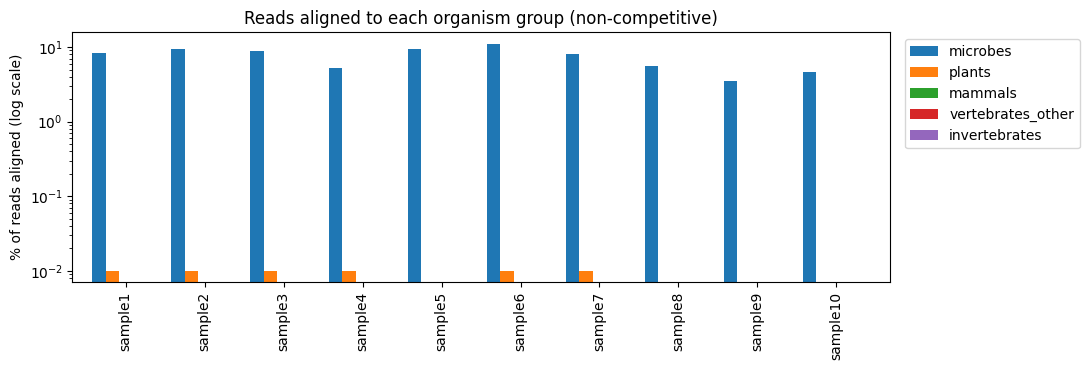

In [16]:
rates = {}
for s in SAMPLES_RUN:
    rates[s] = {}
    for g in GROUPS:
        f = f"{BAMS}/{s}.{g}.bowtie2.log"
        if os.path.exists(f):
            last = [l for l in open(f) if "overall alignment rate" in l]
            rates[s][g] = float(last[0].split("%")[0]) if last else np.nan
rates = pd.DataFrame(rates).T
display(rates.round(3))
rates.plot.bar(figsize=(11, 3.8), logy=True, width=0.85)
plt.ylabel("% of reads aligned (log scale)"); plt.title("Reads aligned to each organism group (non-competitive)")
plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left"); plt.tight_layout(); plt.show()

A look inside a merged BAM: the alignments of one read come one after the other, possibly to references of **different groups**. Column 3 is the reference, column 6 the CIGAR string, and the `NM:i:` tag the edit distance.

In [17]:
%%bash
samtools view "$BAMS/sample10.merged.bam" 2>/dev/null | head -n 8 | cut -f1,3,4,6 || echo "sample10 not in SAMPLES_RUN"

NC_003197.2:+:1575:1619:44b3-2/1	NC_003197.2	1576	44M
NC_003197.2:+:6101:6140:39b3-2/1	NC_003197.2	6102	39M
NC_003197.2:+:9489:9520:31b3-2/1	NC_003197.2	9490	31M
NC_003197.2:+:12441:12486:45b3-2/1	NC_003197.2	12442	45M
NC_003197.2:+:12706:12750:44b3-2/1	NC_003197.2	12707	44M
NC_003197.2:+:13094:13137:43b3-2/1	NC_003197.2	13095	43M
NC_003197.2:+:14188:14259:71b3-2/1	NC_003197.2	14189	71M
NC_003197.2:+:16043:16092:49b3-2/1	NC_003197.2	16044	49M


---
## 4. Taxonomic profiling with ngsLCA

### 4.1 The ngsLCA main program

| Option | Meaning |
|---|---|
| `-bam` | the merged, **read-name-sorted** BAM of one sample |
| `-names`, `-nodes` | the NCBI taxonomy (`names.dmp`, `nodes.dmp`) |
| `-acc2tax` | our accession → taxID table |
| `-simscorelow 0.95 -simscorehigh 1.0` | use only alignments with **95–100 % similarity** to the reference (similarity = 1 − edit distance / read length). Alternatively, `-editdistmin`/`-editdistmax` set an absolute window in mismatches |
| `-minmapq 0` | minimum mapping quality – 0 keeps multi-mapping reads, which is what the LCA needs |
| `-fix_ncbi 0` | ngsLCA can work around a naming problem of old NCBI taxonomy versions; not needed with a current taxonomy |
| `-outnames` | prefix of the output files; the result is `<prefix>.lca` |

In [18]:
%%bash
cd "$LCA"
for sample in $SAMPLES_RUN; do
  [ -s ${sample}.lca ] && { echo "${sample}: done"; continue; }
  ngsLCA -bam "$BAMS/${sample}.merged.bam" -names "$DB/taxonomy/names.dmp" -nodes "$DB/taxonomy/nodes.dmp" \
         -acc2tax "$DB/acc2tax.txt" -simscorelow 0.95 -simscorehigh 1.0 -minmapq 0 -fix_ncbi 0 \
         -outnames ${sample} > ${sample}.ngsLCA.log 2>&1
  echo "${sample}: $(wc -l < ${sample}.lca) reads assigned"
done
ls -lh "$LCA" | head

sample1: 49266 reads assigned
sample2: 41787 reads assigned
sample3: 47021 reads assigned
sample4: 25253 reads assigned
sample5: 53992 reads assigned
sample6: 67733 reads assigned
sample7: 53347 reads assigned
sample8: 38891 reads assigned
sample9: 22996 reads assigned
sample10: 33459 reads assigned
total 179M
-rw------- 1 root root  239 Nov 27 13:36 acc2tax.txtsample10.merged.bam.bin
-rw------- 1 root root  239 Nov 27 13:34 acc2tax.txtsample1.merged.bam.bin
-rw------- 1 root root  239 Nov 27 13:35 acc2tax.txtsample2.merged.bam.bin
-rw------- 1 root root  239 Nov 27 13:35 acc2tax.txtsample3.merged.bam.bin
-rw------- 1 root root  239 Nov 27 13:35 acc2tax.txtsample4.merged.bam.bin
-rw------- 1 root root  239 Nov 27 13:35 acc2tax.txtsample5.merged.bam.bin
-rw------- 1 root root  239 Nov 27 13:35 acc2tax.txtsample6.merged.bam.bin
-rw------- 1 root root  239 Nov 27 13:36 acc2tax.txtsample7.merged.bam.bin
-rw------- 1 root root  239 Nov 27 13:36 acc2tax.txtsample8.merged.bam.bin


### 4.2 The `.lca` format

One line per **read**. Column 1 contains read information separated by colons (read ID, the read sequence, its length and the number of alignments); column 2 is the **assigned LCA** as `taxID:name:rank`; the remaining columns are the full taxonomic path above it.

In [19]:
%%bash
head -n 3 "$LCA/sample10.lca" 2>/dev/null | cut -c 1-400 || echo "run sample10 to see an example"

	-> ngslca version: 0.9 (htslib: 1.24) build(Dec 15 2024 08:12:14)
# -bam /content/drive/MyDrive/AEMG01/14_ALIGN_BAM/sample10.merged.bam -names /content/drive/MyDrive/AEMG01/13_ALIGN_DB/taxonomy/names.dmp -nodes /content/drive/MyDrive/AEMG01/13_ALIGN_DB/taxonomy/nodes.dmp -acc2tax /content/drive/MyDrive/AEMG01/13_ALIGN_DB/acc2tax.txt -simscorelow 0.95 -simscorehigh 1.0 -minmapq 0 -fix_ncbi 0 -outnames sample10
NC_003197.2:+:1575:1619:44b3-2/1:GCGAAATTTTTCGCCGCGCTGGCGCGGGCTAATATCAATATCAT:44:1	99287:Salmonella enterica subsp. enterica serovar Typhimurium str. LT2:strain	90371:Salmonella enterica subsp. enterica serovar Typhimurium:no rank	59201:Salmonella enterica subsp. enterica:subspecies	28901:Salmonella enterica:species	590:Salmonella:genus	543:Enterobacteriaceae:family	91347:Enterobacterales:order	12


Let's read all `.lca` files with Python and summarise them. For each read we take the assigned node (column 2) and determine its **organism group** from the taxonomic path (Bacteria, Archaea, Viridiplantae, Metazoa, …). We also look at the **rank** at which reads are assigned: a read assigned to a genus, family or higher could not be placed on a single species – the LCA is conservative by design.

group,Bacteria,Metazoa,Viridiplantae,other / root
sample1,49251,0,0,14
sample2,41768,0,2,16
sample3,46989,0,0,31
sample4,25242,1,0,9
sample5,53978,0,0,13
sample6,67719,0,0,13
sample7,53335,0,0,11
sample8,38883,0,0,7
sample9,22986,0,0,9
sample10,33449,0,0,9


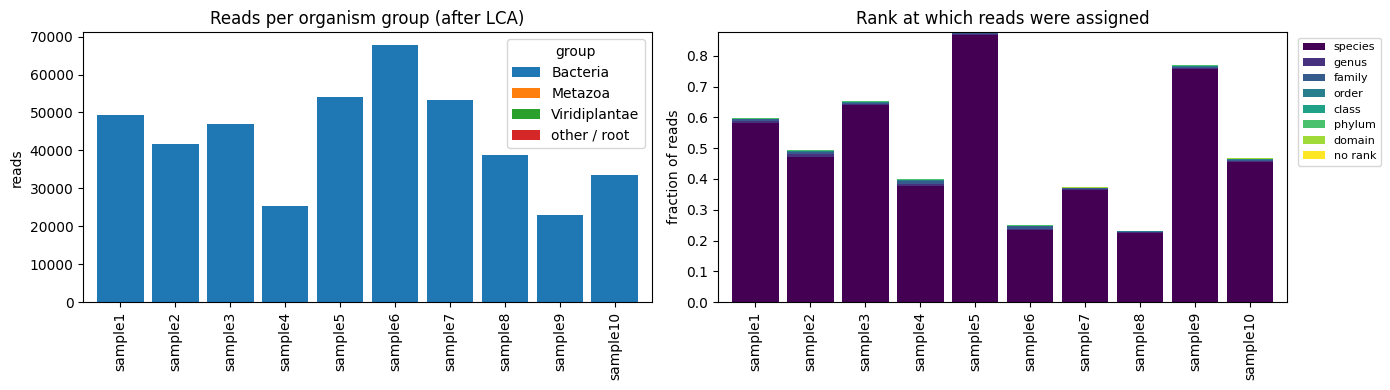

In [20]:
TOP = ["Bacteria", "Archaea", "Viridiplantae", "Metazoa", "Fungi", "Viruses"]

def parse_lca(path):
    rows = []
    with open(path) as f:
        for line in f:
            cols = line.rstrip("\n").split("\t")
            if len(cols) < 2 or ":" not in cols[1]:
                continue
            parts = cols[1].split(":")
            taxid, rank, name = parts[0], parts[-1], ":".join(parts[1:-1])
            path_names = [(c.split(":")[1] if c.count(":") >= 2 else c).strip('"') for c in cols[1:]]
            group = next((t for t in TOP if t in path_names), "other / root")
            rows.append((taxid, name.strip('"'), rank, group))
    return pd.DataFrame(rows, columns=["taxid", "name", "rank", "group"])

lca = {s: parse_lca(f"{LCA}/{s}.lca") for s in SAMPLES_RUN if os.path.exists(f"{LCA}/{s}.lca")}

groups = pd.DataFrame({s: d["group"].value_counts() for s, d in lca.items()}).fillna(0).astype(int).T
ranks  = pd.DataFrame({s: d["rank"].value_counts(normalize=True) for s, d in lca.items()}).fillna(0).T
display(groups)

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
groups.plot.bar(stacked=True, ax=ax[0], logy=False, width=0.85); ax[0].set_ylabel("reads"); ax[0].set_title("Reads per organism group (after LCA)")
keep = [r for r in ["species", "genus", "family", "order", "class", "phylum", "superkingdom", "domain", "no rank"] if r in ranks.columns]
ranks[keep].plot.bar(stacked=True, ax=ax[1], width=0.85, colormap="viridis"); ax[1].set_ylabel("fraction of reads")
ax[1].set_title("Rank at which reads were assigned"); ax[1].legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

And the taxonomic profile: reads per assigned taxon (**LCA node**) and sample, for the 25 most abundant nodes, on a log scale.

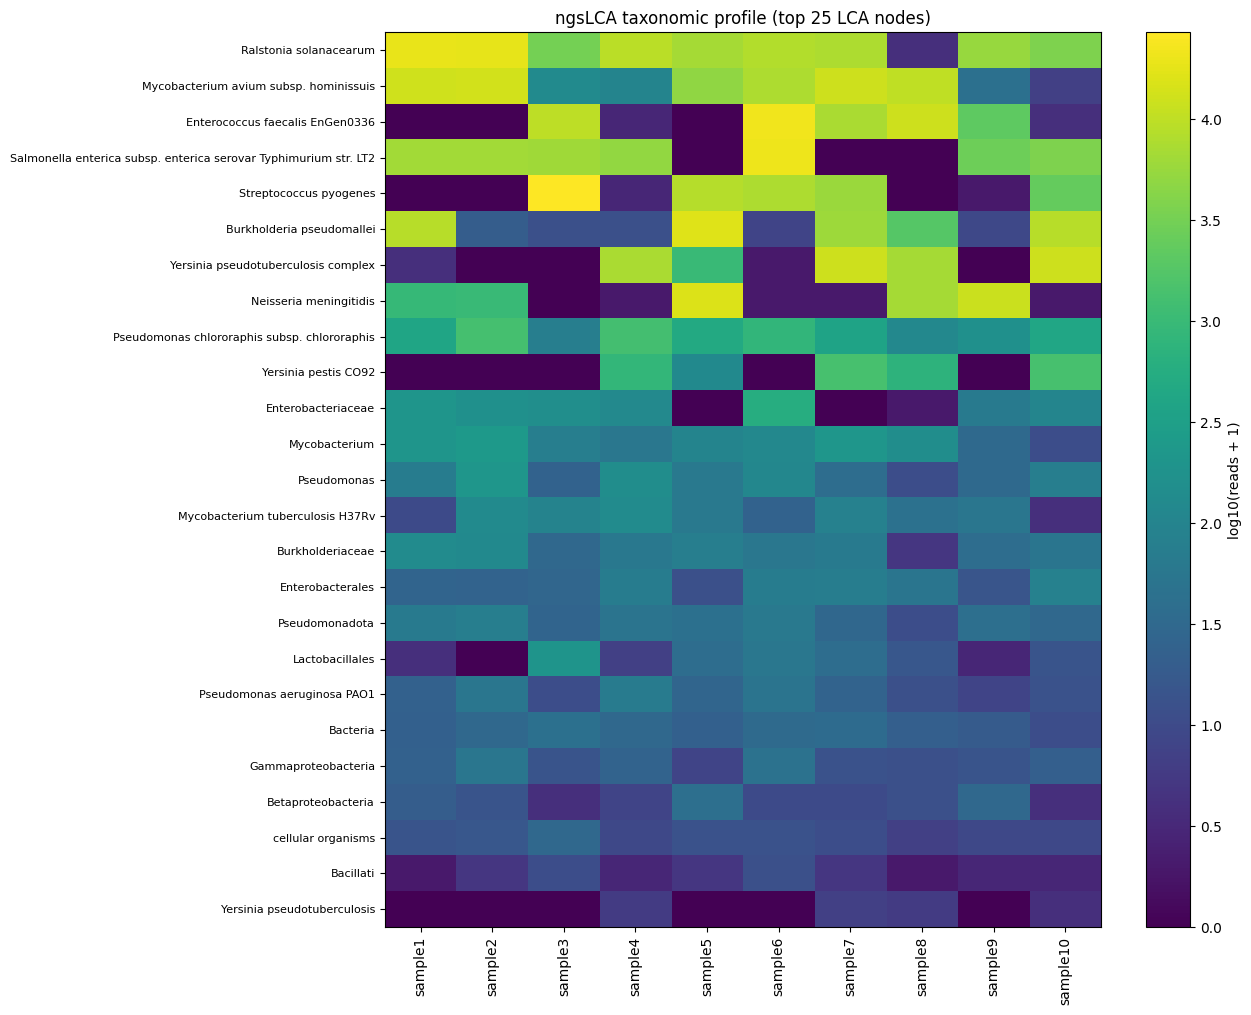

In [21]:
prof = pd.DataFrame({s: d.groupby("name").size() for s, d in lca.items()}).fillna(0)
top = prof.loc[prof.sum(axis=1).sort_values(ascending=False).index[:25]]
m = np.log10(top + 1)
plt.figure(figsize=(0.9 * m.shape[1] + 4, 0.33 * m.shape[0] + 2))
plt.imshow(m, aspect="auto", cmap="viridis"); plt.colorbar(label="log10(reads + 1)")
plt.xticks(range(m.shape[1]), m.columns, rotation=90); plt.yticks(range(m.shape[0]), m.index, fontsize=8)
plt.title("ngsLCA taxonomic profile (top 25 LCA nodes)"); plt.tight_layout(); plt.show()
prof.to_csv(f"{LCA}/ngsLCA_profile_python.tsv", sep="\t")

❓ **Questions**
1. Which groups do the reads fall into? Are there any plant or animal reads, and which taxa are they assigned to? (Hint: human mitochondrial reads.)
2. What fraction of reads is assigned at species level? Why are so many reads of the *Yersinia* species assigned to the *Y. pseudotuberculosis* complex or the genus instead?
3. Re-run ngsLCA for one sample with `-editdistmin 0 -editdistmax 0` (only perfect matches). How does the rank distribution change? Why is a strict window risky for **damaged** ancient reads?

### 4.3 The ngsLCA R package: profiles, filters and plots

The R package turns the `.lca` files into tables and figures. It expects all `.lca` files in **one folder**, and optionally a **metadata** file (tab-separated: lca file name, sample name, a numeric value used to order samples – e.g. depth or age; we use the sample number). The functions run in sequence on the same `path` and `run` (a sub-folder created for the results):

| Function | What it does |
|---|---|
| `ngsLCA_profile(path, run, metadata)` | combines all `.lca` files into one taxa × samples table (`complete_profile.txt`) – required first |
| `ngsLCA_filter(path, run, threshold.1, threshold.2, threshold.3)` | removes taxa with too little read support (minimum-read thresholds; see `?ngsLCA_filter`) |
| `ngsLCA_group(path, run, group.name)` | splits the profile into user-defined groups, e.g. `"Bacteria,Viridiplantae,Metazoa"` |
| `ngsLCA_rank(path, run, rank.name)` | summarises the profiles at chosen ranks (species, genus, family) |
| `ngsLCA_count(path, run)` | counts reads and taxa per sample |
| `ngsLCA_heatmap`, `ngsLCA_barplot`, `ngsLCA_stratplot` | heatmaps, bar plots and **stratigraphic** plots (taxa along a core, ordered by the metadata value) |

(`ngsLCA_deContam` would remove taxa found in blank controls – Day 4 – if blank `.lca` files were available.)

In [22]:
import shutil as _sh
lca_dir = f"{LCA}/lca_files"
os.makedirs(lca_dir, exist_ok=True)
meta = []
for s in lca:
    _sh.copy(f"{LCA}/{s}.lca", f"{lca_dir}/{s}.lca")
    meta.append((f"{s}.lca", s, int("".join(ch for ch in s if ch.isdigit()) or 0)))
pd.DataFrame(meta).to_csv(f"{LCA}/sample_metadata.txt", sep="\t", header=False, index=False)
os.environ["LCA_DIR"] = lca_dir
print(open(f"{LCA}/sample_metadata.txt").read())

sample1.lca	sample1	1
sample2.lca	sample2	2
sample3.lca	sample3	3
sample4.lca	sample4	4
sample5.lca	sample5	5
sample6.lca	sample6	6
sample7.lca	sample7	7
sample8.lca	sample8	8
sample9.lca	sample9	9
sample10.lca	sample10	10



In [23]:
%%writefile /content/ngsLCA_workflow.R
suppressMessages(library(ngsLCA))
path <- paste0(Sys.getenv("LCA_DIR"), "/")
run  <- "run01"
ngsLCA_profile(path = path, run = run, metadata = file.path(Sys.getenv("LCA"), "sample_metadata.txt"))
ngsLCA_filter(path = path, run = run, threshold.1 = 2, threshold.2 = 0, threshold.3 = 5)
ngsLCA_group(path = path, run = run, group.name = "Bacteria,Viridiplantae,Metazoa", threshold.perGroup = 0)
ngsLCA_rank(path = path, run = run, rank.name = "species,genus,family")
ngsLCA_count(path = path, run = run)
ngsLCA_heatmap(path = path, run = run, taxa.number = 30)
ngsLCA_barplot(path = path, run = run, taxa.number = 20)
ngsLCA_stratplot(path = path, run = run, taxa.number = 20)

Writing /content/ngsLCA_workflow.R


In [24]:
%%bash
cd "$LCA_DIR"
if ! PATH=$ENVS/renv/bin:$PATH Rscript -e 'library(ngsLCA)' > /dev/null 2>&1; then
  echo "⚠️ ngsLCA R package is not installed – re-run the installation cell in Section 1.3 (or skip this section)."
else
  PATH=$ENVS/renv/bin:$PATH Rscript /content/ngsLCA_workflow.R > ngsLCA_R.log 2>&1 || { echo "❌ R workflow failed:"; tail -n 20 ngsLCA_R.log; }
fi
echo "results:"; find run01 -type f | sort | head -n 40

Process is terminated.


In [25]:
pdfs = sorted(glob.glob(f"{LCA}/lca_files/run01/**/*.pdf", recursive=True))
for i, p in enumerate(pdfs):
    print(i, os.path.relpath(p, WORKDIR))
if pdfs:
    show_file(os.path.relpath(pdfs[0], WORKDIR), height=700)   # change the index to open another plot

❓ Open the heatmap, the bar plot and the stratigraphic plot of the **genus-level** profile. How do they compare with the KrakenUniq abundance matrix of Day 2?

---
## 5. Damage for every taxon with metaDMG

metaDMG-cpp runs in three steps per sample:

**Step 1 – `lca`:** the LCA (same algorithm as ngsLCA) plus, for every taxon, the counts of all substitution types at every position from the read ends.

| Option | Meaning |
|---|---|
| `--bam` | merged, read-sorted BAM |
| `--names`, `--nodes`, `--acc2tax` | taxonomy and accession → taxID table (gzipped) |
| `--sim_score_low 0.95 --sim_score_high 1.0` | the similarity window, as in ngsLCA |
| `--how_many 15` | number of positions from each read end to record substitutions for |
| `--weight_type 1` | how reads are weighted when counting substitutions (as in the metaDMG documentation examples) |
| `--fix_ncbi 0` | no work-around for old NCBI taxonomy files |
| `--threads`, `--out_prefix` | threads and output prefix |

Outputs: `<prefix>.bdamage.gz` (substitution counts per taxon), `<prefix>.stat.gz` (read statistics per taxon: number of reads, mean length, GC …) and the per-read LCA.

**Step 2 – `dfit`:** fits the damage model to every taxon. `--lib ds` = double-stranded library (C→T at 5′ and G→A at 3′ ends); `--showfits 2` writes the fitted and observed values per position too (needed for damage plots). This is the quick beta-binomial fit; a slower full fit with bootstrap uncertainties is available (`--nopt`, `--nbootstrap`, `--doboot`).

**Step 3 – `aggregate`:** combines the statistics of step 1 and the fits of step 2 and sums them **up the taxonomic tree**, so that every genus, family … gets its own damage estimate. Output: `<prefix>.agg.stat.gz`.

In [26]:
%%bash
cd "$DMG"
[ -x "$MDMG" ] || { echo "❌ metaDMG-cpp not found (MDMG=$MDMG) – check the install cell"; exit 1; }
for sample in $SAMPLES_RUN; do
  [ -s ${sample}.agg.stat.gz ] && { echo "${sample}: done"; continue; }
  "$MDMG" lca --bam "$BAMS/${sample}.merged.bam" --names "$DB/taxonomy/names.dmp" --nodes "$DB/taxonomy/nodes.dmp" \
          --acc2tax "$DB/acc2tax.txt.gz" --sim_score_low 0.95 --sim_score_high 1.0 --how_many 15 \
          --weight_type 1 --fix_ncbi 0 --threads $THREADS --out_prefix ${sample} > ${sample}.lca.log 2>&1
  "$MDMG" dfit ${sample}.bdamage.gz --names "$DB/taxonomy/names.dmp" --nodes "$DB/taxonomy/nodes.dmp" \
          --showfits 2 --lib ds --out ${sample} > ${sample}.dfit.log 2>&1
  "$MDMG" aggregate ${sample}.bdamage.gz --lcastat ${sample}.stat.gz --names "$DB/taxonomy/names.dmp" \
          --nodes "$DB/taxonomy/nodes.dmp" --dfit ${sample}.dfit.gz --out ${sample}.agg > ${sample}.agg.log 2>&1
  echo "$(date +%H:%M:%S)  ${sample}: $(ls ${sample}* | tr '\n' ' ')"
done

13:40:56  sample1: sample1.agg.log sample1.agg.stat.gz sample1.bdamage.gz sample1.dfit.gz sample1.dfit.log sample1.famoutreads.bam sample1.lca.gz sample1.lca.log sample1.rlens.gz sample1.stat.gz sample1.usedreads.bam 
13:42:35  sample2: sample2.agg.log sample2.agg.stat.gz sample2.bdamage.gz sample2.dfit.gz sample2.dfit.log sample2.famoutreads.bam sample2.lca.gz sample2.lca.log sample2.rlens.gz sample2.stat.gz sample2.usedreads.bam 
13:44:03  sample3: sample3.agg.log sample3.agg.stat.gz sample3.bdamage.gz sample3.dfit.gz sample3.dfit.log sample3.famoutreads.bam sample3.lca.gz sample3.lca.log sample3.rlens.gz sample3.stat.gz sample3.usedreads.bam 
13:45:40  sample4: sample4.agg.log sample4.agg.stat.gz sample4.bdamage.gz sample4.dfit.gz sample4.dfit.log sample4.famoutreads.bam sample4.lca.gz sample4.lca.log sample4.rlens.gz sample4.stat.gz sample4.usedreads.bam 
13:47:13  sample5: sample5.agg.log sample5.agg.stat.gz sample5.bdamage.gz sample5.dfit.gz sample5.dfit.log sample5.famoutreads.b

Combine the aggregated tables of all samples into one data frame (we add a `sample` column), and look at the main columns: `name`, `rank`, `nreads`, `mean_rlen` (mean read length), and the damage parameters `A`, `q`, `c`, `phi` and `Zfit`.

In [27]:
tabs = []
for s in SAMPLES_RUN:
    f = (glob.glob(f"{DMG}/{s}.agg*stat*gz") or [None])[0]
    if f:
        t = pd.read_csv(f, sep="\t")
        t.insert(0, "sample", s); tabs.append(t)
dmg = pd.concat(tabs, ignore_index=True) if tabs else pd.DataFrame()
for c in ["nreads", "A", "q", "c", "phi", "Zfit", "mean_rlen"]:
    if c in dmg: dmg[c] = pd.to_numeric(dmg[c], errors="coerce")
print(dmg.shape, "\ncolumns:", list(dmg.columns)[:30], "…")
if len(dmg) and "rank" in dmg:
    cols = [c for c in ["sample", "name", "rank", "nreads", "mean_rlen", "A", "q", "c", "Zfit"] if c in dmg.columns]
    display(dmg[(dmg["rank"] == "species") & (dmg.nreads >= 100)][cols].sort_values(["sample", "nreads"], ascending=[True, False]).head(30))
else:
    print("no metaDMG results – check the logs in 16_METADMG/")

/tmp/ipykernel_4946/2779487107.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  t.insert(0, "sample", s); tabs.append(t)
/tmp/ipykernel_4946/2779487107.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  t.insert(0, "sample", s); tabs.append(t)
/tmp/ipykernel_4946/2779487107.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, us

(556, 172) 
columns: ['sample', 'taxid', 'name', 'rank', 'nalign', 'nreads', 'mean_rlen', 'var_rlen', 'mean_gc', 'var_gc', 'lca', 'taxa_path', 'A', 'q', 'c', 'phi', 'llh', 'ncall', 'sigmaD_old', 'Zfit_old', 'sigmaD_new', 'Zfit_new', 'fwK0', 'fwN0', 'fwf0', 'fwdx0', 'fwdxConf0', 'fwK1', 'fwN1', 'fwf1'] …


,sample,name,rank,nreads,mean_rlen,A,q,c
4,sample1,Ralstonia solanacearum,species,18887,46.088158,0.115843,0.428712,0.012480
17,sample1,Mycobacterium avium,species,12970,46.014957,0.139457,0.412277,0.006828
20,sample1,Burkholderia pseudomallei,species,8817,71.109673,0.000977,0.322154,0.002978
21,sample1,Salmonella enterica,species,6436,45.673553,0.152703,0.407409,0.006831
8,sample1,Neisseria meningitidis,species,940,45.474468,0.149261,0.393000,0.010099
44,sample1,Pseudomonas chlororaphis,species,394,67.718277,0.023112,0.019752,0.000000
521,sample10,Burkholderia pseudomallei,species,9031,71.528732,0.002185,0.467686,0.002692
497,sample10,Ralstonia solanacearum,species,3803,46.188797,0.114355,0.382641,0.010999
522,sample10,Salmonella enterica,species,3795,45.727009,0.170793,0.477210,0.007191
512,sample10,Streptococcus pyogenes,species,2364,45.605331,0.149859,0.390858,0.004472


**Damage vs significance.** Every point is a taxon in a sample (species level, ≥ 100 reads). Taxa in the upper right – high damage `A` and high significance `Zfit` – are the candidates for **ancient** organisms; taxa with `A` ≈ 0 are modern or contaminants. The SPAAM textbook suggests treating `Zfit > 2` with at least ~100 reads as significant; small damage values need many more reads to be detected reliably.

**Damage smiley plots from metaDMG.** With `--showfits 2`, the tables contain, for every taxon, the observed C→T frequencies per position from the 5′ end (`fwf…`) and the fitted model (`fwdx…`), and the same for G→A from the 3′ end (`bwf…`, `bwdx…`). We plot them for the 6 most abundant species with significant damage.

59 species x sample combinations with at least 100 reads


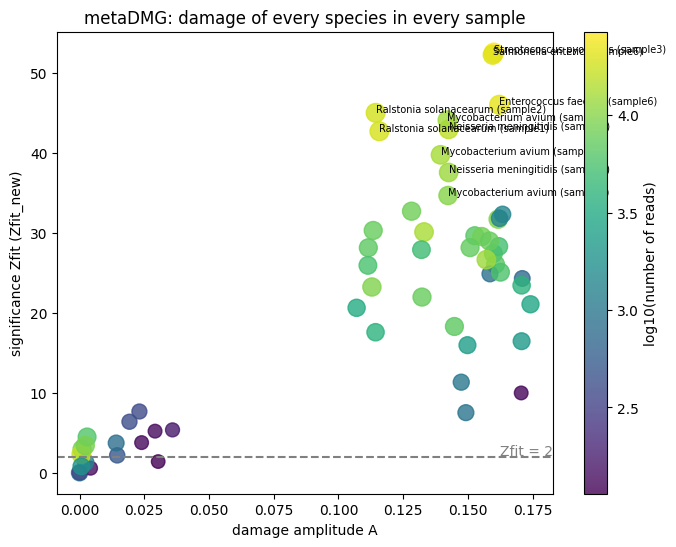

In [32]:
import os, glob, re, numpy as np, pandas as pd, matplotlib.pyplot as plt

def pick(df, *names):
    norm = {re.sub(r"[^a-z0-9]", "", c.lower()): c for c in df.columns}
    for n in names:
        c = norm.get(re.sub(r"[^a-z0-9]", "", n.lower()))
        if c is not None:
            return c
    return None

d = dmg.copy()

# 1) if the aggregated table lacks the damage fit, take it from the .dfit files
if pick(d, "Zfit", "Zfit_new", "Zfit_old") is None or pick(d, "A") is None:
    fits = []
    for f in glob.glob(f"{DMG}/*.dfit*gz"):
        t = pd.read_csv(f, sep="\t", dtype=str)
        t["sample"] = os.path.basename(f).split(".dfit")[0]
        fits.append(t)
    if fits:
        fit = pd.concat(fits, ignore_index=True)
        kf, kd = pick(fit, "taxid", "id"), pick(d, "taxid", "id")
        if kf and kd:
            fit = fit.rename(columns={kf: kd})
            fit[kd] = fit[kd].astype(str).str.strip()
            d[kd] = d[kd].astype(str).str.strip()
            d["sample"] = d["sample"].astype(str)
            keep = [c for c in fit.columns if c in (kd, "sample") or c not in d.columns]
            d = d.merge(fit[keep], on=[kd, "sample"], how="left")
            print("fit columns taken from the .dfit files")

# 2) columns (metaDMG-cpp 0.5 reports Zfit_new and Zfit_old; we use Zfit_new)
cA = pick(d, "A")
cZ = pick(d, "Zfit", "Zfit_new", "Zfit_old")
cN = pick(d, "nreads")
cR = pick(d, "rank")
cNm = pick(d, "name")
if cZ and "Zfit" not in d.columns:
    d["Zfit"] = d[cZ]

if None in (cA, cZ, cN, cR, cNm):
    print("ERROR: could not find all columns. Available columns:")
    print(list(d.columns))
else:
    for c in (cA, cZ, cN):
        d[c] = pd.to_numeric(d[c], errors="coerce")
    sp = d[(d[cR] == "species") & (d[cN] >= 100)].dropna(subset=[cA, cZ])
    print(len(sp), "species x sample combinations with at least 100 reads")
    if len(sp):
        plt.figure(figsize=(8, 6))
        sc = plt.scatter(sp[cA], sp[cZ], s=12 + 40 * np.log10(sp[cN]),
                         c=np.log10(sp[cN]), cmap="viridis", alpha=0.8)
        plt.colorbar(sc, label="log10(number of reads)")
        plt.axhline(2, ls="--", c="grey")
        plt.text(plt.xlim()[1], 2.2, "Zfit = 2", ha="right", color="grey")
        top = sp.sort_values(cZ, ascending=False).head(10)
        for _, r in top.iterrows():
            plt.annotate(str(r[cNm]) + " (" + str(r["sample"]) + ")", (r[cA], r[cZ]), fontsize=7)
        plt.xlabel("damage amplitude A")
        plt.ylabel("significance Zfit (Zfit_new)")
        plt.title("metaDMG: damage of every species in every sample")
        plt.show()
    dmg = d

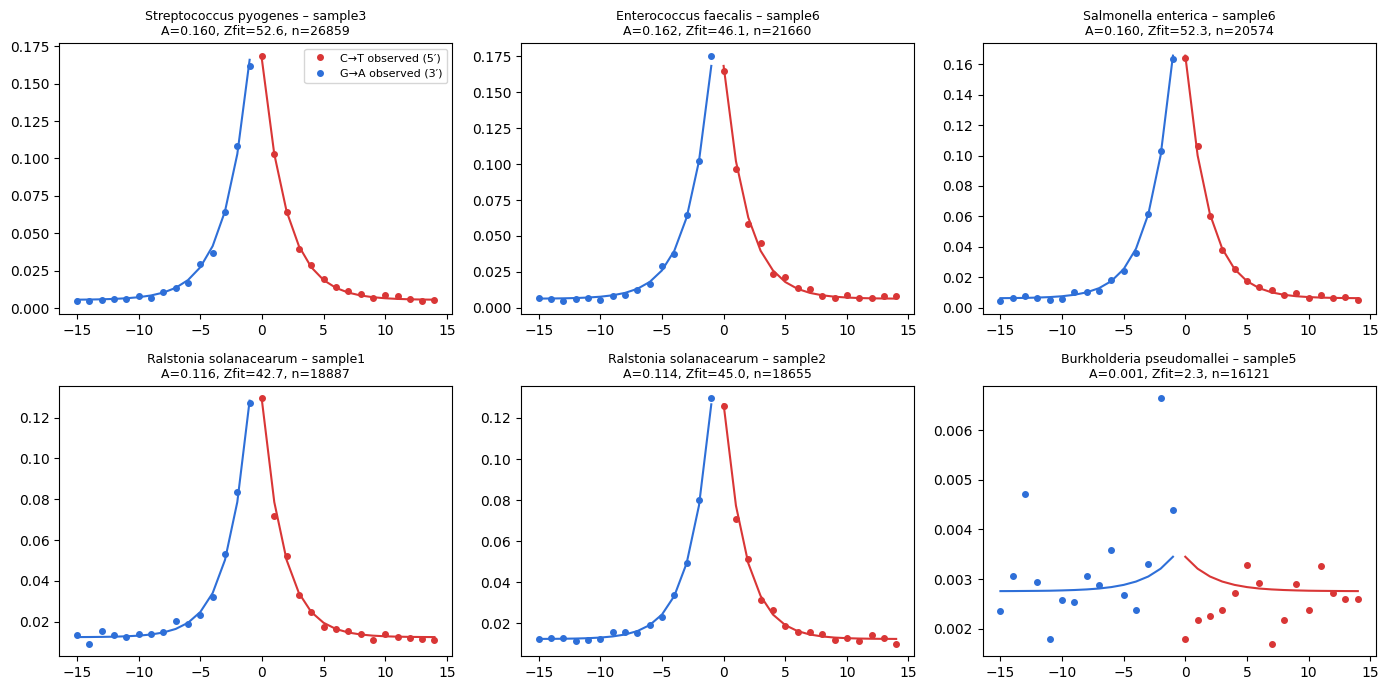

In [33]:
def series(row, prefix):
    cols = sorted([c for c in row.index if c.startswith(prefix) and c[len(prefix):].isdigit()], key=lambda c: int(c[len(prefix):]))
    return np.array([row[c] for c in cols], dtype=float)

cand = sp[sp.Zfit > 2].sort_values("nreads", ascending=False).head(6) if len(sp) else sp
if len(cand) and any(c.startswith("fwf") for c in dmg.columns):
    fig, axes = plt.subplots(2, 3, figsize=(14, 7), squeeze=False)
    for ax, (_, r) in zip(axes.flat, cand.iterrows()):
        f_obs, f_fit = series(r, "fwf"), series(r, "fwdx")
        b_obs, b_fit = series(r, "bwf"), series(r, "bwdx")
        x = np.arange(len(f_obs))
        ax.plot(x, f_obs, "o", color="#D93636", ms=4, label="C→T observed (5′)")
        if len(f_fit) == len(x): ax.plot(x, f_fit, "-", color="#D93636")
        if len(b_obs) == len(x):
            ax.plot(-x - 1, b_obs, "o", color="#2E6FD8", ms=4, label="G→A observed (3′)")
            if len(b_fit) == len(x): ax.plot(-x - 1, b_fit, "-", color="#2E6FD8")
        ax.set_title(f"{r['name']} – {r['sample']}\nA={r.A:.3f}, Zfit={r.Zfit:.1f}, n={int(r.nreads)}", fontsize=9)
    axes[0, 0].legend(fontsize=8); plt.tight_layout(); plt.show()
else:
    print("No significant species, or no per-position columns (run dfit with --showfits 2).")

❓ **Questions**
1. Which species show significant damage, and in which samples? Is *Yersinia pestis* among them?
2. Compare the damage of the same species across samples. Do all samples contain the ancient form of a species?
3. Why do taxa at higher ranks (genus, family) usually have *more* reads and *more precise* damage estimates than the species in them?

---
## 6. Authentication metrics per taxon with bamdam

bamdam reads the merged BAM together with the **ngsLCA `.lca` file** of the same sample.

**`bamdam shrink`** removes alignments of taxa with too few reads, so that the later steps are fast:

| Option | Meaning |
|---|---|
| `--in_bam`, `--in_lca` | read-sorted BAM and its ngsLCA output |
| `--out_bam`, `--out_lca` | the smaller files |
| `--stranded ds` | double-stranded library (`ss` for single-stranded) – determines which substitutions count as damage |
| `--mincount 5` | keep taxa with at least 5 reads (default) |
| `--upto family` | consider taxa up to family level (default) |

**`bamdam compute`** produces the per-taxon table (`--out_tsv`) and the substitution counts (`--out_subs`) used for damage plots. Its columns include `TotalReads`, `Duplicity`, `MeanDust` (read complexity), `Damage+1` (C→T at the first position), `Damage-1` (G→A at the last position), `MeanLength`, `ANI` (average identity to the reference), `AvgReadGC`, `UniqueKmers` and the taxonomic path.

In [34]:
%%bash
cd "$BD"
for sample in $SAMPLES_RUN; do
  [ -s ${sample}.tsv ] && { echo "${sample}: done"; continue; }
  [ -s "$LCA/${sample}.lca" ] || { echo "${sample}: no ngsLCA output – run Section 4"; continue; }
  bamdam shrink --in_bam "$BAMS/${sample}.merged.bam" --in_lca "$LCA/${sample}.lca" \
                --out_bam ${sample}.shrunk.bam --out_lca ${sample}.shrunk.lca --stranded ds --mincount 5 --upto family \
                > ${sample}.shrink.log 2>&1
  bamdam compute --in_bam ${sample}.shrunk.bam --in_lca ${sample}.shrunk.lca \
                 --out_tsv ${sample}.tsv --out_subs ${sample}.subs.txt --stranded ds --upto family \
                 > ${sample}.compute.log 2>&1
  echo "${sample}: $(($(wc -l < ${sample}.tsv) - 1)) taxa, BAM $(du -h "$BAMS/${sample}.merged.bam" | cut -f1) -> $(du -h ${sample}.shrunk.bam | cut -f1)"
done

sample1: 36 taxa, BAM 3.5M -> 3.0M
sample2: 32 taxa, BAM 3.4M -> 2.5M
sample3: 36 taxa, BAM 2.9M -> 2.5M
sample4: 39 taxa, BAM 2.6M -> 2.0M
sample5: 34 taxa, BAM 4.4M -> 3.8M
sample6: 40 taxa, BAM 4.3M -> 3.7M
sample7: 36 taxa, BAM 4.3M -> 3.8M
sample8: 36 taxa, BAM 3.0M -> 2.8M
sample9: 36 taxa, BAM 2.1M -> 1.7M
sample10: 42 taxa, BAM 3.1M -> 2.8M


In [35]:
bd = {s: pd.read_csv(f"{BD}/{s}.tsv", sep="\t") for s in SAMPLES_RUN if os.path.exists(f"{BD}/{s}.tsv")}
s0 = "sample10" if "sample10" in bd else next(iter(bd), None)
if s0:
    t = bd[s0]
    show = [c for c in ["TaxNodeID", "TaxName", "TotalReads", "Damage+1", "Damage-1", "MeanLength", "Duplicity", "MeanDust", "ANI", "UniqKmersPerRead"] if c in t.columns]
    print(f"bamdam compute – {s0}")
    display(t[show].sort_values("TotalReads", ascending=False).head(20))

bamdam compute – sample10


,TaxNodeID,TaxName,TotalReads,Damage+1,Damage-1,MeanLength,Duplicity,MeanDust,ANI,UniqKmersPerRead
0,1649845,Yersinia pseudotuberculosis complex,13601,0.1644,0.1601,45.63,1.05,1.86,0.9930,16.748
1,629,Yersinia,13601,0.1644,0.1601,45.63,1.05,1.86,0.9930,16.748
2,1903411,Yersiniaceae,13601,0.1644,0.1601,45.63,1.05,1.86,0.9930,16.748
3,119060,Burkholderiaceae,12886,0.0322,0.0461,63.96,1.05,3.23,0.9907,34.235
4,28450,Burkholderia pseudomallei,9031,0.0028,0.0060,71.53,1.05,3.56,0.9951,41.407
5,111527,pseudomallei group,9031,0.0028,0.0060,71.53,1.05,3.56,0.9951,41.407
6,32008,Burkholderia,9031,0.0028,0.0060,71.53,1.05,3.56,0.9951,41.407
7,543,Enterobacteriaceae,3897,0.1719,0.1777,45.65,1.01,1.91,0.9926,17.522
8,305,Ralstonia solanacearum,3803,0.1076,0.1465,46.19,1.00,2.45,0.9801,18.104
9,3116862,Ralstonia solanacearum species complex,3803,0.1076,0.1465,46.19,1.00,2.45,0.9801,18.104


**Combine the samples** into one matrix with `bamdam combine` (`--in_tsv_list` = a text file listing the tables, `--minreads 50` = report taxa with at least 50 reads, `--include` = extra metrics to add as columns), and plot **damage against read length** for all taxa – ancient taxa combine high damage with short reads.

In [36]:
%%bash
cd "$BD"
ls *.tsv | grep -v combined > tsv_list.txt
bamdam combine --in_tsv_list tsv_list.txt --out_tsv combined.tsv --minreads 50 > combine.log 2>&1 && head -n 5 combined.tsv | cut -c 1-250

TaxNodeID	TaxName	TotalReads	AvgDuplicity	AvgMeanDust	AvgDamage+1	sample1_TotalReads	sample1_Duplicity	sample1_MeanDust	sample1_Damage+1	sample10_TotalReads	sample10_Duplicity	sample10_MeanDust	sample10_Damage+1	sample2_TotalReads	sample2_Duplicity	s
119060	"Burkholderiaceae"	124778	1.0423	2.8156	0.0834	27839	1.05	2.79	0.0873	12886	1.05	3.23	0.0322	18801	1.02	2.46	0.1255	3276	1.0	2.45	0.1128	9571	1.03	2.45	0.1288	23002	1.08	3.2	0.0364	8304	1.02	2.45	0.1315	13716	1.04	2.94	0.0672	1812	1.01	3.52	0.
305	"Ralstonia solanacearum"	82229	1.0258	2.4516	0.1261	18887	1.04	2.45	0.1294	3803	1.0	2.45	0.1076	18655	1.03	2.46	0.1258	3235	1.0	2.46	0.1143	9501	1.03	2.45	0.1294	6804	1.03	2.43	0.1234	8240	1.02	2.45	0.1313	7576	1.02	2.45	0.12	2	1.06	1.04	0.0	5526
3116862	"Ralstonia solanacearum species complex"	82229	1.0258	2.4516	0.1261	18887	1.04	2.45	0.1294	3803	1.0	2.45	0.1076	18655	1.03	2.46	0.1258	3235	1.0	2.46	0.1143	9501	1.03	2.45	0.1294	6804	1.03	2.43	0.1234	8240	1.02	2.45	0.1313	7576	1.02	2.45	0.

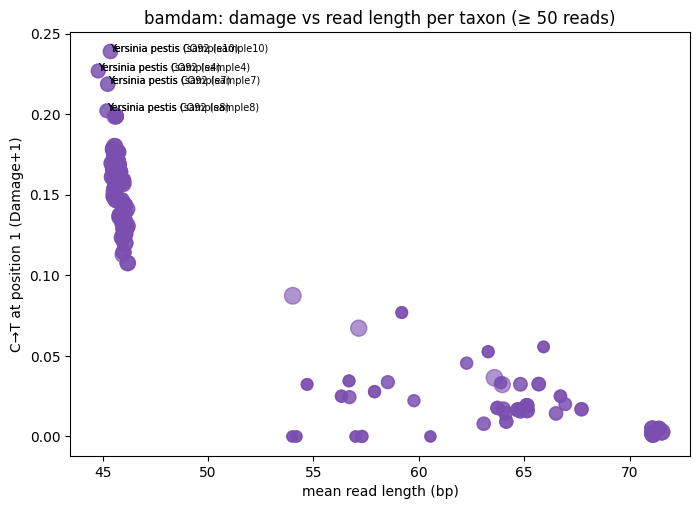

In [37]:
allbd = pd.concat([t.assign(sample=s) for s, t in bd.items()], ignore_index=True) if bd else pd.DataFrame()
if len(allbd) and "Damage+1" in allbd:
    a = allbd[allbd.TotalReads >= 50]
    plt.figure(figsize=(8, 5.5))
    plt.scatter(a.MeanLength, a["Damage+1"], s=10 + 30 * np.log10(a.TotalReads), alpha=0.6, c="#7B4FB0")
    for _, r in a.sort_values("Damage+1", ascending=False).head(8).iterrows():
        plt.annotate(f"{r.TaxName} ({r['sample']})", (r.MeanLength, r["Damage+1"]), fontsize=7)
    plt.xlabel("mean read length (bp)"); plt.ylabel("C→T at position 1 (Damage+1)")
    plt.title("bamdam: damage vs read length per taxon (≥ 50 reads)"); plt.show()

**Damage plot for one taxon across samples.** `bamdam plotdamage` draws the "smiley" plot from the substitution files of one or more samples for a taxon given by its **numeric taxID** (`--tax`; *Yersinia pestis* = 632). Change `TAX` to inspect other taxa from the tables above.

pping this file.


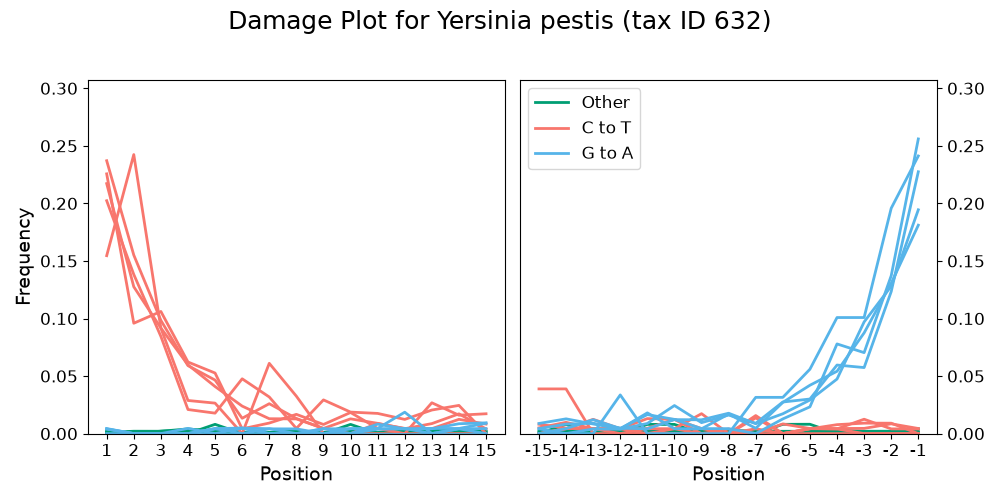

In [38]:
TAX = 632
subs = [f"{BD}/{s}.subs.txt" for s in bd]
open(f"{BD}/subs_list.txt", "w").write("\n".join(subs) + "\n")
r = subprocess.run(["bamdam", "plotdamage", "--in_subs_list", f"{BD}/subs_list.txt", "--tax", str(TAX),
                    "--outplot", f"{BD}/damage_tax{TAX}.png"], capture_output=True, text=True)
print((r.stdout + r.stderr).strip()[-500:])
if os.path.exists(f"{BD}/damage_tax{TAX}.png"):
    display(Image(filename=f"{BD}/damage_tax{TAX}.png", width=700))

**Extract the reads of one taxon** and plot their mismatch and read-length distributions: `bamdam extract` writes the reads assigned to `--tax` (here in sample10) to a new BAM, and `bamdam plotbaminfo` plots that BAM.

In [39]:
%%bash
cd "$BD"
s=sample10; tax=632
[ -s ${s}.shrunk.bam ] || { echo "sample10 not analysed"; exit 0; }
bamdam extract --in_bam ${s}.shrunk.bam --in_lca ${s}.shrunk.lca --out_bam ${s}.tax${tax}.bam --tax ${tax} > extract.log 2>&1
bamdam plotbaminfo --in_bam ${s}.tax${tax}.bam --outplot ${s}.tax${tax}.baminfo.png > plotbaminfo.log 2>&1
echo "reads of taxon ${tax}: $(samtools view -c ${s}.tax${tax}.bam 2>/dev/null)"

reads of taxon 632: 1881


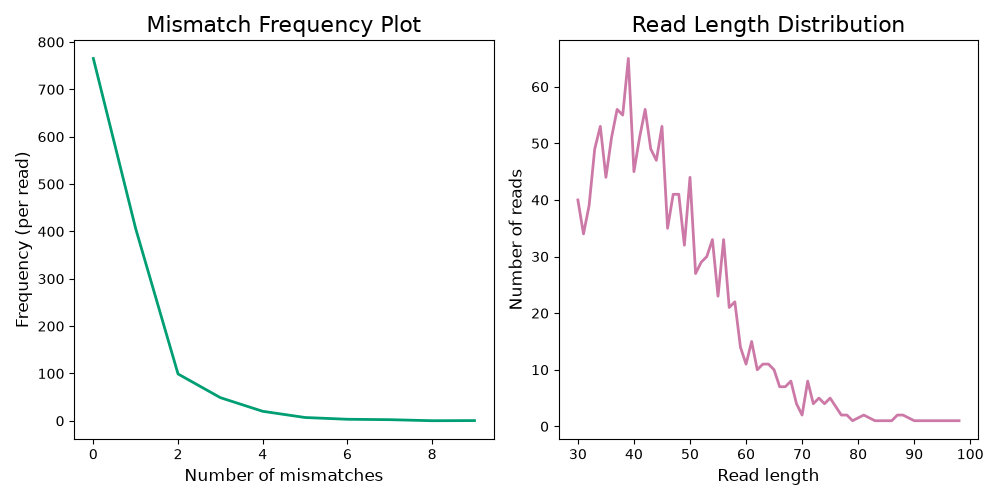

In [40]:
f = f"{BD}/sample10.tax632.baminfo.png"
display(Image(filename=f, width=800)) if os.path.exists(f) else print("no plot – see 17_BAMDAM/plotbaminfo.log")

**An interactive Krona chart** of all samples, coloured by damage: `bamdam krona` writes Krona XML (`--minreads` minimum reads per taxon, `--aggregate_to` the rank up to which taxa are shown), and KronaTools' `ktImportXML` turns it into an HTML page, which we open with `show_file`.

In [41]:
%%bash
cd "$BD"
bamdam krona --in_tsv_list tsv_list.txt --out_xml krona.xml --minreads 20 > krona.log 2>&1 \
  && ktImportXML -o krona.html krona.xml > /dev/null 2>&1 && ls -lh krona.html || tail -n 5 krona.log

Error: No valid input files remain after filtering. Exiting.


In [42]:
if os.path.exists(f"{BD}/krona.html"):
    show_file(os.path.relpath(f"{BD}/krona.html", WORKDIR), height=750)

❓ **Questions**
1. Which taxa combine **high damage**, **short reads**, **low duplicity** and **high complexity** (low DUST)? Those are your best candidates for authentic ancient taxa.
2. Do bamdam's damage values (`Damage+1`) agree with metaDMG's `A` for the same taxon and sample?
3. A taxon has many reads but very high duplicity and low complexity. What could explain that?

---
## 7. Comparing with the k-mer profile of Day 2 (optional)

Which genera are found by both approaches? We compare the genera of sample10 with ≥ 50 reads in the ngsLCA profile with those of the filtered KrakenUniq profile of Day 2.

In [43]:
s = "sample10"
ku_file = f"05_TAXONOMIC_PROFILE/{s}.krakenuniq.output"
if s in lca and os.path.exists(ku_file):
    g_lca = set(lca[s][lca[s]["rank"] == "genus"].groupby("name").size().loc[lambda x: x >= 50].index)
    ku = pd.read_csv(ku_file, sep="\t", comment="#", dtype=str)
    for c in ["taxReads", "kmers", "reads"]:
        ku[c] = pd.to_numeric(ku[c], errors="coerce")
    ku["taxName"] = ku["taxName"].str.strip()
    g_ku = set(ku[(ku["rank"] == "genus") & (ku.reads >= 50)].taxName)
    print("both          :", sorted(g_lca & g_ku))
    print("only ngsLCA   :", sorted(g_lca - g_ku))
    print("only KrakenUniq:", sorted(g_ku - g_lca)[:30])
else:
    print("needs sample10 in SAMPLES_RUN and the Day 2 KrakenUniq output")

both          : ['Pseudomonas']
only ngsLCA   : []
only KrakenUniq: ['Burkholderia', 'Campylobacter', 'Clostridium', 'Mycolicibacterium', 'Ralstonia', 'Rhodococcus', 'Salmonella', 'Streptococcus', 'Streptomyces', 'Yersinia']


❓ Why can the ngsLCA profile only contain organisms that are in our small reference database, while KrakenUniq found many more? What does this tell you about the importance of the **reference database** for alignment-based profiling?

---
## Summary

* **Alignment-based profiling** needs only one reference **index chunk** in memory at a time: databases can be split (e.g. by organism group, or into chunks of NCBI nt/RefSeq), aligned to separately and merged – trading memory for time and disk. This is how sedaDNA studies screen for plants and animals (Holi pipeline).
* Alignments to separate indexes are **non-competitive**; merging the read-sorted BAMs and computing the **LCA over all hits** makes the assignment conservative again.
* **ngsLCA** assigns each read to the LCA of all hits within a **similarity window**; its R package filters, groups and plots the profiles (heatmaps, bar plots, stratigraphic plots).
* **metaDMG** computes the LCA *and* fits a **damage model to every taxon** (A, q, c, phi, Zfit), making damage-based authentication routine for whole metagenomes.
* **bamdam** adds per-taxon **authentication metrics** (damage, read length, duplicity, complexity, ANI), damage plots, read extraction and Krona charts.

## Questions to think about
1. When would you choose k-mer classification (Day 2) and when alignment + LCA (today)?
2. Why is it essential to report multiple alignments per read (`-k`) and to keep reads with MAPQ 0 for LCA-based profiling?
3. How would you choose the similarity window for very old, heavily damaged reads?
4. What are the risks of an **incomplete** reference database for LCA-based profiling of plants and animals?

## References
* **ngsLCA**: Wang Y., Korneliussen T.S., Holman L.E., Manica A., Pedersen M.W. (2022) ngsLCA – A toolkit for fast and flexible lowest common ancestor inference and taxonomic profiling of metagenomic data. *Methods in Ecology and Evolution* 13:2699–2708, [doi:10.1111/2041-210X.14006](https://doi.org/10.1111/2041-210X.14006) · [GitHub](https://github.com/miwipe/ngsLCA) · [R package](https://cran.r-project.org/package=ngsLCA)
* **metaDMG**: Michelsen C., Pedersen M.W., Fernandez-Guerra A., Zhao L., Petersen T.C., Korneliussen T.S. (2022) metaDMG – A Fast and Accurate Ancient DNA Damage Toolkit for Metagenomic Data. *bioRxiv*, [doi:10.1101/2022.12.06.519264](https://doi.org/10.1101/2022.12.06.519264) · [metaDMG-cpp](https://github.com/metaDMG-dev/metaDMG-cpp) · [documentation](https://metadmg-dev.github.io/metaDMG-core/)
* **bamdam**: De Sanctis B., Mirchandani C., Dong H., Macleod R., Corbett-Detig R., Wang Y. (2025) Bamdam: a post-mapping authentication toolkit for ancient metagenomics. *Genome Biology*, [doi:10.1186/s13059-025-03879-x](https://doi.org/10.1186/s13059-025-03879-x) · [GitHub](https://github.com/bdesanctis/bamdam)
* **Holi pipeline / sedaDNA at scale**: Wang Y. et al. (2021) Late Quaternary dynamics of Arctic biota from ancient environmental genomics. *Nature* 600:86–92, [doi:10.1038/s41586-021-04016-x](https://doi.org/10.1038/s41586-021-04016-x)
* **Damage model**: Briggs A.W. et al. (2007) Patterns of damage in genomic DNA sequences from a Neandertal. *PNAS* 104:14616–14621, [doi:10.1073/pnas.0704665104](https://doi.org/10.1073/pnas.0704665104)
* **Textbook chapter** with a full metaDMG workflow: SPAAM community, *Introduction to Ancient Metagenomics*, chapter "Authentication", [spaam-community.org/intro-to-ancient-metagenomics-book](https://www.spaam-community.org/intro-to-ancient-metagenomics-book/authentication.html)

---
## Save this notebook as HTML

Finally, export the notebook – with all its outputs – to a single **HTML file** that you can open in any browser, keep as a record of your work, or share. [`jupyter nbconvert`](https://nbconvert.readthedocs.io/) converts the notebook file (`.ipynb`) to other formats; `--to html` selects HTML, and `--output-dir` writes the result into your own working folder (you cannot write into the instructor's shared folder).

1. **Save the notebook first** (*File ▸ Save*, or Ctrl/Cmd + S): nbconvert converts the file as it is stored in Google Drive.
2. Run the cell below. It looks for `Day5_LCA_damage_shortcut.ipynb` in your Drive (if you opened the notebook from GitHub, use *File ▸ Save a copy in Drive* first, or set `NB_PATH` by hand).

Interactive elements that need a running Colab session – embedded reports served by `show_html()` and IGV views – appear empty in the HTML file; tables, plots and printed output are kept.

In [44]:
import glob, os, shutil, subprocess, sys
NB_NAME = "Day5_LCA_damage_shortcut.ipynb"
NB_PATH = None   # <- set by hand if the search below does not find the notebook

if NB_PATH is None:
    pats = [f"/content/drive/MyDrive/{NB_NAME}", f"/content/drive/MyDrive/*/{NB_NAME}",
            f"/content/drive/MyDrive/*/*/{NB_NAME}"]
    hits = [p for pat in pats for p in glob.glob(pat)]
    NB_PATH = max(hits, key=os.path.getmtime) if hits else None     # the most recently saved copy

OUT_DIR = os.environ.get("WORKDIR", "/content/drive/MyDrive/AEMG01")
if NB_PATH:
    print("converting", NB_PATH)
    # convert a local copy: nbconvert cannot cope with spaces in the path (e.g. "… (1)" shortcuts)
    os.makedirs("/content/nb_export", exist_ok=True)
    local_nb = shutil.copy(NB_PATH, f"/content/nb_export/{NB_NAME}")
    args = ["--to", "html", local_nb, "--output-dir", OUT_DIR]
    # use the `jupyter` command if it exists, otherwise nbconvert as a Python module
    cmd = ["jupyter", "nbconvert"] + args if shutil.which("jupyter") else [sys.executable, "-m", "nbconvert"] + args
    r = subprocess.run(cmd, capture_output=True, text=True)
    if r.returncode != 0 and "No module named nbconvert" in r.stderr:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "nbconvert"])
        r = subprocess.run([sys.executable, "-m", "nbconvert"] + args, capture_output=True, text=True)
    print(r.stderr.strip().splitlines()[-1] if r.stderr.strip() else r.stdout)
    html = os.path.join(OUT_DIR, NB_NAME.replace(".ipynb", ".html"))
    print(("✅ HTML file: " if os.path.exists(html) else "❌ conversion failed – see the message above: ") + html)
else:
    print(f"{NB_NAME} not found in your Drive – save a copy in Drive (File ▸ Save a copy in Drive) or set NB_PATH")

converting /content/drive/MyDrive/AncientEnvironmentalMetagenomics/Day5_LCA_damage_shortcut.ipynb
[NbConvertApp] Writing 1478824 bytes to /content/drive/MyDrive/AEMG01/Day5_LCA_damage_shortcut.html
✅ HTML file: /content/drive/MyDrive/AEMG01/Day5_LCA_damage_shortcut.html
